# Lab 2 – Windowing in spectral analysis
### Detection and separation of three close sinusoids with different window functions — all 15 variants compared

| | |
|---|---|
| **Author** | Radosław Skrzypczyński — Informatyka II st., niestacjonarne, 1 sem., Gr. 2 |
| **Course** | Digital Signal Processing — prof. dr hab. Vasyl Martsenyuk |
| **Repository** | https://github.com/Slayzerus/dsp-lab2 |

**Task (Sec. 7 of the lab instructions).** Generate the discrete-time signal

x[k] = A₁·sin(2π·f₁/fₛ·k) + A₂·sin(2π·f₂/fₛ·k) + A₃·sin(2π·f₃/fₛ·k),  0 ≤ k < N,

with A₁ = |x[k]|ₘₐₓ from Table 1, A₂ = 0.1·A₁ (−20 dB) and A₃ = 0.01·A₁ (−40 dB). Apply several window
functions before computing the DFT, plot (1) the normalised DFT level of the windowed signals (like Fig. 6)
and (2) the DTFT of the windows normalised to their main-lobe maximum (like Fig. 7), and interpret which
window detects weak tones and separates close frequencies best. **All 15 variants of Table 1 are computed
and compared.**

**Contents.** 1 Background · 2 Helper functions and metrics · 3 Validation against the instructions ·
4 Variants · 5 Window functions · 6 Why f₁, f₂, f₃ look different · 7 Spectra of all variants ·
8 Comparison across variants · 9 Where is which window better · 10 Interpretation · 11 Conclusions

In [1]:
import platform
from pathlib import Path

import numpy as np
import pandas as pd
import scipy
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from matplotlib.lines import Line2D
from matplotlib.ticker import FixedLocator, FixedFormatter
from numpy.fft import fft, fftshift
from scipy.signal import windows as sw
from IPython.display import display

print(f"Python {platform.python_version()} | numpy {np.__version__} | scipy {scipy.__version__} | "
      f"matplotlib {matplotlib.__version__} | pandas {pd.__version__}")

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

Python 3.14.2 | numpy 2.4.1 | scipy 1.18.1 | matplotlib 3.10.8 | pandas 3.0.6


## 1. Background

* **Leakage.** Only N samples are observed, i.e. the signal is multiplied by a window w[k]. In the frequency
  domain this is a convolution with the window's DTFT W(Ω): every sinusoid is replaced by a copy of W centred
  on its frequency — a *main lobe* plus *sidelobes*. A weak component can be hidden under the main lobe or the
  sidelobes of a strong one.
* **The DFT samples the DTFT** at the bins fₖ = k·fₛ/N, spaced Δf = fₛ/N = 1/T with T = N/fₛ the observation
  time. A sine that completes an integer number of periods in N samples (*coherent sampling*) sits exactly on a
  bin: with the rectangular window all other bins hit the zeros of W and the tone is a single line (best case,
  Fig. 1 and Fig. 6 of the instructions). Otherwise the bins sample the main lobe and the sidelobes (worst case
  half a bin off).
* **Trade-off.** Tapered windows lower the sidelobes (less leakage, better detection of weak tones) at the cost
  of a wider main lobe (worse separation of close tones) and a lower coherent gain.
* **Normalisation.** `fft2db` from the instructions scales the DFT by 2/N (sine amplitude, independent of N).
  Here the level is also divided by the window's coherent gain CG = mean(w) and by A₁, so a coherently sampled
  tone of amplitude A₁ reads **0 dB for every window** and the weak tones are expected at **−20 dB** and
  **−40 dB** ("dB re A₁").
* **Aliasing.** A sampled sine at f > fₛ/2 equals ± a sine at the apparent frequency |f − m·fₛ| ≤ fₛ/2. This
  affects every variant (Section 4).

In [2]:
# Plot style: thin marks, recessive solid hairline grid, text in neutral ink (never in series colours).
INK, INK2, MUTED, GRID, AXIS = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
_fonts = {f.name for f in font_manager.fontManager.ttflist}
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "figure.facecolor": "white", "axes.facecolor": "white",
    # explicit family list -> per-glyph fallback to DejaVu Sans (✓, ✗, ▲ are missing in Segoe UI)
    "font.family": [f for f in ("Segoe UI", "DejaVu Sans") if f in _fonts] or ["sans-serif"],
    "font.size": 9, "axes.titlesize": 9.5, "axes.titleweight": "semibold", "axes.titlelocation": "left",
    "axes.labelsize": 9, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "grid.linestyle": "-",
    "xtick.color": AXIS, "ytick.color": AXIS, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "legend.frameon": False, "legend.fontsize": 8, "legend.labelcolor": INK2,
    "lines.linewidth": 1.5, "lines.solid_capstyle": "round", "lines.solid_joinstyle": "round",
    "mathtext.fontset": "dejavusans", "figure.titlesize": 10.5, "figure.titleweight": "semibold",
})

# Fixed categorical order (validated palette: worst adjacent CVD ΔE 9.1, normal-vision ΔE 19.6);
# a window keeps its colour in every figure.
WIN_COLORS = {"Rectangular": "#2a78d6", "Hann": "#eb6834", "Hamming": "#1baf7a",
              "Blackman": "#eda100", "Blackman-Harris": "#e87ba4", "Flat-top": "#008300"}


def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png")
    plt.show()

## 2. Helper functions and comparison metrics

`fft2db` and `winDTFTdB` are taken from Sec. 5.1.1 and 5.2.1 of the instructions (only a −300 dB floor is
added to avoid log₁₀(0)). Windows are periodic (`sym=False`), as recommended for spectral analysis. To compare
the windows objectively, three metrics are computed for each weak tone (f₂ at −20 dB, f₃ at −40 dB):

| Metric | Question | Detected if |
|---|---|---|
| **M1 – DFT visibility** | Does the tone dominate one of the two DFT bins next to its frequency? SLR = 20·log₁₀(\|X_weak[k]\| / \|X_rest[k]\|); the components are transformed separately (the DFT is linear). | SLR ≥ 6 dB |
| **M2 – grid-independent detectability** | Is the tone above the worst-case leakage of all other components within ±0.5 bin of its frequency, read from the window DTFT? D = level − leakage. | D ≥ 6 dB |
| **M3 – separation** | Does the zero-padded (DTFT-like) spectrum show the tone as its own peak — ≥ 6 dB above the spectrum without it and separated from the strong tone by a dip ≥ 3 dB — for all 16 relative phases? | yes / no |

M1 describes what the requested DFT plot actually shows, which depends on where the bins fall. M2 and M3
describe what the window itself allows, independently of the bin grid.

In [3]:
DB_FLOOR = -300.0      # floor of the dB scale (avoids log10(0))
DETECT_DB = 6.0        # detection threshold: the tone must exceed what masks it by a factor of 2
SLR_CAP = 60.0         # display cap for M1: larger values only occur at exact (coherent) nulls
PHASES = np.linspace(0, 2*np.pi, 16, endpoint=False)

WINDOWS = {
    "Rectangular":     lambda N: np.ones(N),
    "Hann":            lambda N: sw.hann(N, sym=False),
    "Hamming":         lambda N: sw.hamming(N, sym=False),
    "Blackman":        lambda N: sw.blackman(N, sym=False),
    "Blackman-Harris": lambda N: sw.blackmanharris(N, sym=False),
    "Flat-top":        lambda N: sw.flattop(N, sym=False),
}


def to_db(x):
    """20·log10|x| with a floor."""
    return 20*np.log10(np.maximum(np.abs(x), 10**(DB_FLOOR/20)))


def fft2db(X):
    """DFT level normalised to sine amplitudes - as in Sec. 5.1.1 of the instructions."""
    N = X.size
    Xtmp = 2/N * X           # independent of N, norm for sine amplitudes
    Xtmp[0] *= 1/2           # bin for f = 0 Hz exists only once
    if N % 2 == 0:           # fs/2 is included as a bin and exists only once
        Xtmp[N//2] = Xtmp[N//2] / 2
    return to_db(Xtmp)


def winDTFTdB(w):
    """Quasi-DTFT of a window by 100x zero-padding, normalised to the main-lobe maximum (Sec. 5.2.1)."""
    N = w.size
    Nz = 100*N
    W = np.zeros(Nz)
    W[0:N] = w
    W = np.abs(fftshift(fft(W)))
    W /= np.max(W)
    W = to_db(W)
    Omega = 2*np.pi/Nz*np.arange(Nz) - np.pi
    return Omega, W


def level_re_A1(x, w, A1):
    """DFT level of the windowed signal in dB re A1, corrected for the coherent gain of the window."""
    return fft2db(fft(x*w)) - 20*np.log10(w.mean()) - 20*np.log10(A1)


def zp_level_re_A1(x, w, A1, pad=32):
    """Zero-padded (DTFT-like) spectrum with the same scaling as level_re_A1.
    fft2db cannot be reused here: it would normalise by the padded length."""
    X = fft(x*w, pad*x.size)
    return to_db(2*X/np.sum(w)) - 20*np.log10(A1)


def alias(f, fs):
    """Apparent frequency in [0, fs/2] and the sign a sampled sine acquires:
    sin(2π·f/fs·k) = s·sin(2π·fa/fs·k) for integer k."""
    m = np.round(f/fs)
    fd = f - m*fs
    return abs(fd), (-1.0 if fd < 0 else 1.0)


AMP_RATIOS = np.array([1.0, 0.1, 0.01])        # A1, A2 = 0.1·A1, A3 = 0.01·A1


def components(v, N=None, shift_bins=0.0):
    """The three sampled tones of variant v (rows of the returned array); optionally a different N
    or all frequencies shifted by a fraction of a DFT bin."""
    N = int(v.N) if N is None else int(N)
    fs = float(v.fs)
    k = np.arange(N)
    A = AMP_RATIOS*float(v.Amax)
    f = np.array([v.f1, v.f2, v.f3], dtype=float) + shift_bins*fs/N
    return A, f, A[:, None]*np.sin(2*np.pi*f[:, None]/fs*k)


# ---------- M1: what the DFT plot shows ----------
def m1_slr(comps, i, w, fa_i, fs):
    """Signal-to-leakage ratio of weak tone i on the two DFT bins bracketing its apparent frequency."""
    N = w.size
    Xi = np.abs(fft(comps[i]*w))
    Xr = np.abs(fft((comps.sum(axis=0) - comps[i])*w))
    b = fa_i*N/fs
    bins = sorted({int(np.floor(b)), int(np.ceil(b))})
    return min(max(to_db(Xi[k]) - to_db(Xr[k]) for k in bins), SLR_CAP)


# ---------- M2: detectability independent of the DFT grid ----------
class WinMag:
    """|W(u)|/|W(0)| of a window on a fine grid (P points per bin); u in DFT bins, periodic in N."""
    def __init__(self, w, P=64):
        self.N, self.P = w.size, P
        Wm = np.abs(fft(w, P*w.size))
        self.mag = Wm/Wm[0]

    def __call__(self, u):
        idx = np.round(np.asarray(u)*self.P).astype(np.int64) % (self.P*self.N)
        return self.mag[idx]


def m2_detectability(wm, fa, r, i, fs, N, half=0.5):
    """D = 20log10(r_i) - E: E is the worst case (max within ±half bin of tone i) of the summed window
    responses of all other tones and of the negative-frequency images of all tones."""
    pos = np.asarray(fa)*N/fs
    u = np.arange(pos[i] - half, pos[i] + half + 1e-9, 1/wm.P)
    env = np.zeros_like(u)
    for j in range(len(fa)):
        if j != i:
            env += r[j]*wm(u - pos[j])
        env += r[j]*wm(u + pos[j])                  # image at -fa_j (= fs - fa_j)
    return 20*np.log10(r[i]) - to_db(env.max())


# ---------- M3: separation on the zero-padded spectrum ----------
def _resolved(S, R, i_lo, i_hi, i_strong):
    """S, R: dB spectra with / without the weak tone, one row per relative phase. The weak tone's peak is the
    maximum of S within ±0.5 bin of its frequency; it must exceed R there by >= 6 dB and be separated from the
    strong tone by a dip of >= 3 dB."""
    rows = np.arange(S.shape[0])
    j = i_lo + np.argmax(S[:, i_lo:i_hi + 1], axis=1)
    peak = S[rows, j]
    dominates = peak - R[rows, j] >= DETECT_DB
    dip = np.array([S[p, min(i_strong, j[p]):max(i_strong, j[p]) + 1].min() <= peak[p] - 3.0 for p in rows])
    return dominates & dip


def m3_resolved(A, f, fs, N, i, w, P=32):
    """True if weak tone i is resolved for every one of the 16 relative phases."""
    k = np.arange(N)
    rest = sum(A[j]*np.sin(2*np.pi*f[j]/fs*k) for j in range(len(A)) if j != i)
    Xr = fft(rest*w, P*N)
    Xs = fft(A[i]*np.sin(2*np.pi*f[i]/fs*k)*w, P*N)
    Xc = fft(A[i]*np.cos(2*np.pi*f[i]/fs*k)*w, P*N)
    b_i, b_1 = alias(f[i], fs)[0]*N/fs, alias(f[0], fs)[0]*N/fs
    lo = int(np.floor((min(b_i, b_1) - 1.5)*P))
    hi = int(np.ceil((max(b_i, b_1) + 1.5)*P))
    sl = slice(lo, hi + 1)
    ph = PHASES[:, None]
    S = to_db(Xr[None, sl] + np.cos(ph)*Xs[None, sl] + np.sin(ph)*Xc[None, sl])
    R = np.broadcast_to(to_db(Xr[sl]), S.shape)
    i_lo = int(np.ceil((b_i - 0.5)*P)) - lo
    i_hi = int(np.floor((b_i + 0.5)*P)) - lo
    return bool(_resolved(S, R, i_lo, i_hi, int(round(b_1*P)) - lo).all())

## 3. Validation against the instructions

The helper functions reproduce the example of Sec. 3–5 of the instructions (f₁ = 200 Hz, f₂ = 200.25 Hz,
fₛ = 800 Hz, N = 1600) and its Fig. 6: without coherent-gain correction the best-case peaks are 0 dB
(rectangular), −6.02 dB (Hann) and −13.33 dB (flat-top), and the worst case (half a bin off) loses 3.92 dB
with the rectangular window.

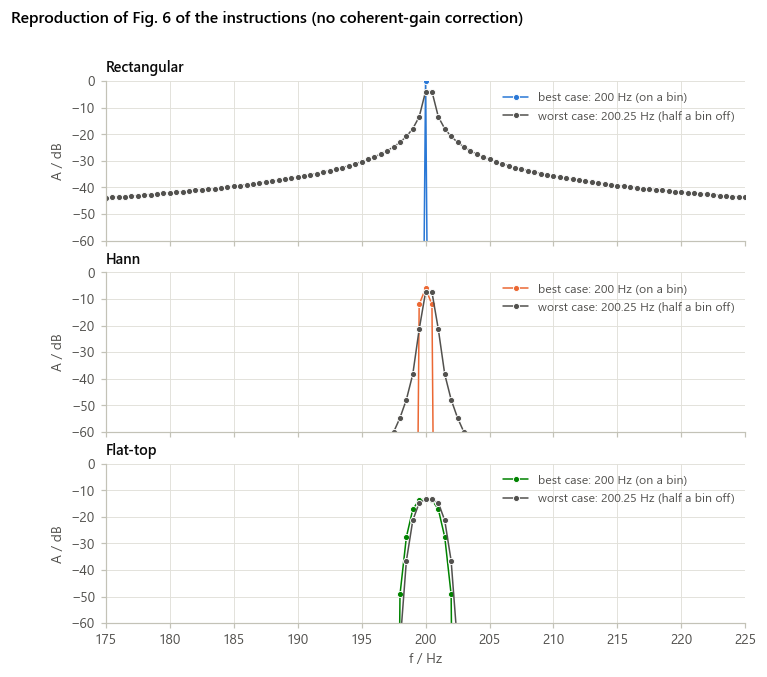

                      Rectangular  Hann  Flat-top
best-case peak [dB]          0.00 -6.02    -13.33
worst-case peak [dB]        -3.92 -7.44    -13.34


In [4]:
f_a, f_b, fs_v, N_v = 200, 200.25, 800, 1600
k_v = np.arange(N_v)
x_best = np.sin(2*np.pi*f_a/fs_v*k_v)
x_worst = np.sin(2*np.pi*f_b/fs_v*k_v)
f_v = np.arange(N_v)*fs_v/N_v

fig, axs = plt.subplots(3, 1, figsize=(7.5, 6.4), sharex=True)
checks = {}
for ax, name in zip(axs, ["Rectangular", "Hann", "Flat-top"]):
    w = WINDOWS[name](N_v)
    Lb, Lw = fft2db(fft(x_best*w)), fft2db(fft(x_worst*w))
    checks[name] = (Lb.max(), Lw.max())
    ax.plot(f_v, Lb, "o-", color=WIN_COLORS[name], ms=4, lw=1, mec="white", mew=0.6,
            label=f"best case: {f_a} Hz (on a bin)")
    ax.plot(f_v, Lw, "o-", color=INK2, ms=4, lw=1, mec="white", mew=0.6,
            label=f"worst case: {f_b} Hz (half a bin off)")
    ax.set(xlim=(175, 225), ylim=(-60, 0), ylabel="A / dB")
    ax.set_xticks(np.arange(175, 230, 5))
    ax.set_yticks(np.arange(-60, 10, 10))
    ax.set_title(name)
    ax.legend(loc="upper right")
axs[-1].set_xlabel("f / Hz")
fig.suptitle("Reproduction of Fig. 6 of the instructions (no coherent-gain correction)", x=0.01, ha="left")
save(fig, "fig01_fig6_reproduction")

print(pd.DataFrame(checks, index=["best-case peak [dB]", "worst-case peak [dB]"]).round(2))
assert abs(checks["Rectangular"][0]) < 0.01 and abs(checks["Hann"][0] + 6.02) < 0.01
assert abs(checks["Flat-top"][0] + 13.33) < 0.01 and abs(checks["Rectangular"][1] + 3.92) < 0.01

## 4. Variants (Table 1) and derived quantities

In [5]:
VARIANTS = pd.DataFrame(
    [(1, 300, 300.25, 299.75, 2, 400, 2000), (2, 400, 400.25, 399.75, 2, 600, 3000),
     (3, 500, 500.25, 499.75, 2, 800, 1800), (4, 600, 600.25, 599.75, 2, 500, 2000),
     (5, 300, 300.25, 299.75, 2, 400, 2000), (6, 600, 600.25, 599.75, 3, 800, 2000),
     (7, 400, 400.25, 399.75, 3, 600, 3000), (8, 500, 500.25, 499.75, 3, 800, 1800),
     (9, 600, 600.25, 599.75, 3, 500, 2000), (10, 300, 300.25, 299.75, 3, 400, 2000),
     (11, 200, 200.25, 199.75, 4, 400, 2000), (12, 400, 400.25, 399.75, 4, 600, 3000),
     (13, 500, 500.25, 499.75, 4, 800, 1800), (14, 600, 600.25, 599.75, 4, 500, 2000),
     (15, 500, 500.25, 499.75, 4, 800, 2000)],
    columns=["No", "f1", "f2", "f3", "Amax", "fs", "N"]).set_index("No")

# Variants with identical (f1, f2, f3, fs, N) give identical spectra in dB re A1 -> configurations C1..C7.
_key = VARIANTS[["f1", "f2", "f3", "fs", "N"]].apply(tuple, axis=1)
_order = list(dict.fromkeys(_key))
CONFIG = _key.map({kk: f"C{i + 1}" for i, kk in enumerate(_order)})
CONFIGS = {f"C{i + 1}": list(CONFIG.index[_key == kk]) for i, kk in enumerate(_order)}

table1 = VARIANTS.rename(columns={"Amax": "|x|max = A1", "fs": "fs [Hz]",
                                  "f1": "f1 [Hz]", "f2": "f2 [Hz]", "f3": "f3 [Hz]"})
table1["configuration"] = CONFIG
display(table1)


def derived(cfg):
    v = VARIANTS.loc[CONFIGS[cfg][0]]
    fs, N = float(v.fs), int(v.N)
    fa = [alias(x, fs) for x in (v.f1, v.f2, v.f3)]
    return pd.Series({
        "variants": ", ".join(map(str, CONFIGS[cfg])),
        "fs [Hz]": fs, "N": N, "T = N/fs [s]": N/fs, "Δf = fs/N [Hz]": fs/N,
        "Nyquist violated (some f ≥ fs/2)": bool(max(v.f1, v.f2, v.f3) >= fs/2),
        "apparent f1 / f2 / f3 [Hz]": " / ".join(f"{a[0]:.2f}" for a in fa),
        "mirrored": fa[0][1] < 0 or fa[1][1] < 0,
        "periods in N (f1 / f2 / f3)": " / ".join(f"{x*N/fs:g}" for x in (v.f1, v.f2, v.f3)),
        "spacing [bins]": 0.25*N/fs,
    })


DERIVED = pd.DataFrame({c: derived(c) for c in CONFIGS}).T
display(DERIVED)

,f1 [Hz],f2 [Hz],f3 [Hz],|x|max = A1,fs [Hz],N,configuration
No,,,,,,,
1,300,300.25,299.75,2,400,2000,C1
2,400,400.25,399.75,2,600,3000,C2
3,500,500.25,499.75,2,800,1800,C3
4,600,600.25,599.75,2,500,2000,C4
5,300,300.25,299.75,2,400,2000,C1
6,600,600.25,599.75,3,800,2000,C5
7,400,400.25,399.75,3,600,3000,C2
8,500,500.25,499.75,3,800,1800,C3
9,600,600.25,599.75,3,500,2000,C4


,variants,fs [Hz],N,T = N/fs [s],Δf = fs/N [Hz],Nyquist violated (some f ≥ fs/2),apparent f1 / f2 / f3 [Hz],mirrored,periods in N (f1 / f2 / f3),spacing [bins]
C1,"1, 5, 10",400.0,2000,5.0,0.2,True,100.00 / 99.75 / 100.25,True,1500 / 1501.25 / 1498.75,1.25
C2,"2, 7, 12",600.0,3000,5.0,0.2,True,200.00 / 199.75 / 200.25,True,2000 / 2001.25 / 1998.75,1.25
C3,"3, 8, 13",800.0,1800,2.25,0.444444,True,300.00 / 299.75 / 300.25,True,1125 / 1125.56 / 1124.44,0.5625
C4,"4, 9, 14",500.0,2000,4.0,0.25,True,100.00 / 100.25 / 99.75,False,2400 / 2401 / 2399,1.0
C5,6,800.0,2000,2.5,0.4,True,200.00 / 199.75 / 200.25,True,1500 / 1500.62 / 1499.38,0.625
C6,11,400.0,2000,5.0,0.2,True,200.00 / 199.75 / 199.75,True,1000 / 1001.25 / 998.75,1.25
C7,15,800.0,2000,2.5,0.4,True,300.00 / 299.75 / 300.25,True,1250 / 1250.62 / 1249.38,0.625


Observations (computed above):

* **Every variant violates the sampling theorem** (f > fₛ/2), so the tones are observed at aliased frequencies,
  e.g. variant 1: 300 → 100 Hz, 300.25 → 99.75 Hz, 299.75 → 100.25 Hz. For mirrored aliases (all configurations
  except C4) the order of f₂ and f₃ is reversed and the sine changes sign; the 0.25 Hz spacing is preserved, so
  the comparison of windows remains meaningful.
* **A₁ only shifts the absolute level** (the plots are in dB re A₁), and variant 5 is identical to variant 1.
  The 15 variants therefore form **7 configurations C1–C7**. All variants are still computed individually, and
  identical results within a configuration are asserted in Section 8.
* **The configurations differ in the observation time T = N/fₛ:** the tone spacing in DFT bins is
  0.25 Hz·T = 1.25 bins (T = 5 s: C1, C2), 1 bin (T = 4 s: C4), 0.625 bin (T = 2.5 s: C5, C7) and 0.5625 bin
  (T = 2.25 s: C3).
* f₁ always completes an integer number of periods in N samples (coherent sampling); f₂ and f₃ do so only in C4.
* **Variant 11 (C6) is degenerate:** f₁ = fₛ/2 exactly, so A₁·sin(πk) = 0 for every k — the strongest tone is
  not present in the samples at all — and f₂ = 200.25 Hz aliases onto f₃ = 199.75 Hz with opposite sign. The
  sampled signal is a single sine of amplitude |A₃ − A₂| = 0.09·A₁ (verified below).

In [6]:
rows = []
for no, v in VARIANTS.iterrows():
    A, f, comps = components(v)
    k = np.arange(int(v.N))
    ok = True
    for i in range(3):
        fa, s = alias(f[i], v.fs)
        ok &= np.allclose(comps[i], s*A[i]*np.sin(2*np.pi*fa/v.fs*k), atol=1e-7*v.Amax)
    rows.append({"No": no, "sin(2π·f/fs·k) = ±sin(2π·fa/fs·k) for f1, f2, f3": ok})
alias_check = pd.DataFrame(rows).set_index("No")
display(alias_check.T)
alias_check.columns = ["aliasing identity holds"]
assert alias_check["aliasing identity holds"].all()

v11 = VARIANTS.loc[11]
A11, f11, c11 = components(v11)
k11 = np.arange(int(v11.N))
single_tone = (A11[2] - A11[1])*np.sin(2*np.pi*199.75/v11.fs*k11)
print(f"Variant 11: max|x1| = {np.abs(c11[0]).max():.1e};  x == -0.09·A1·sin(2π·199.75/400·k): "
      f"{np.allclose(c11.sum(axis=0), single_tone, atol=1e-9)}")

No,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
"sin(2π·f/fs·k) = ±sin(2π·fa/fs·k) for f1, f2, f3",True,True,True,True,True,True,True,True,True,True,True,True,True,True,True


Variant 11: max|x1| = 2.8e-12;  x == -0.09·A1·sin(2π·199.75/400·k): True


## 5. Window functions

Six windows are compared: rectangular, Hann, Hamming and Blackman (named in the task), Blackman–Harris
(named in Sec. 1 as the window with the highest resolving power for long records) and flat-top (used in the
code of the instructions). All plots use N = 2000.

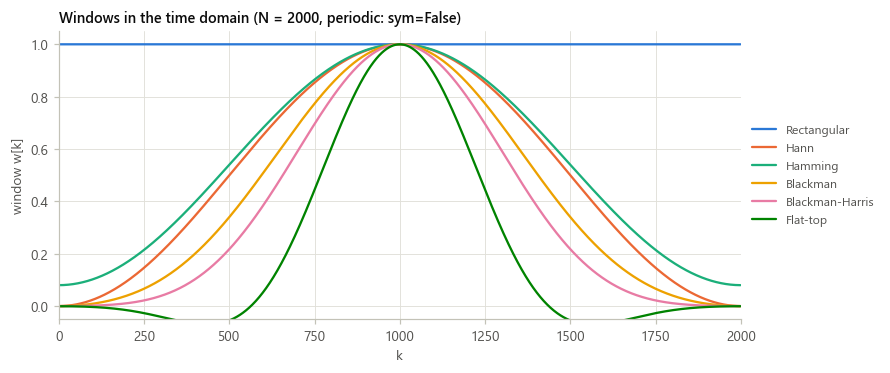

In [7]:
N_w = 2000
fig, ax = plt.subplots(figsize=(8, 3.4))
for name, wf in WINDOWS.items():
    ax.plot(np.arange(N_w), wf(N_w), color=WIN_COLORS[name], lw=1.5, label=name)
ax.set(xlim=(0, N_w), ylim=(-0.05, 1.05), xlabel="k", ylabel="window w[k]")
ax.set_title("Windows in the time domain (N = 2000, periodic: sym=False)")
ax.legend(loc="center left", bbox_to_anchor=(1.0, 0.5))
save(fig, "fig02_windows_time")

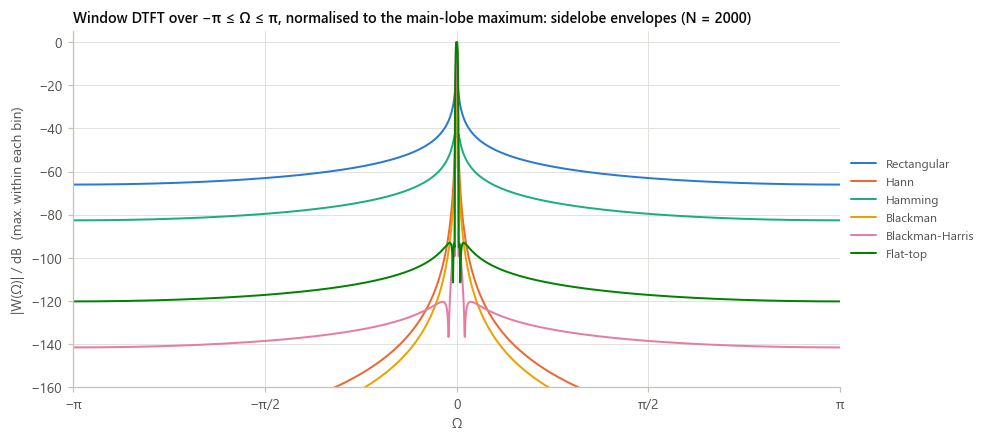

In [8]:
# Over the full range the sidelobes are too dense to draw individually (N = 2000 -> 1000 lobes per side),
# so the upper envelope is plotted: the maximum of winDTFTdB within each DFT bin (100 points per bin).
fig, ax = plt.subplots(figsize=(9, 4.2))
for name, wf in WINDOWS.items():
    Om, Wdb = winDTFTdB(wf(N_w))
    ax.plot(Om.reshape(-1, 100).mean(axis=1), Wdb.reshape(-1, 100).max(axis=1), color=WIN_COLORS[name], lw=1.3,
            label=name)
ax.set(xlim=(-np.pi, np.pi), ylim=(-160, 5), xlabel="Ω", ylabel="|W(Ω)| / dB  (max. within each bin)")
ax.set_xticks([-np.pi, -np.pi/2, 0, np.pi/2, np.pi], ["−π", "−π/2", "0", "π/2", "π"])
ax.set_title("Window DTFT over −π ≤ Ω ≤ π, normalised to the main-lobe maximum: sidelobe envelopes (N = 2000)")
ax.legend(loc="center left", bbox_to_anchor=(1.0, 0.5))
save(fig, "fig03_windows_dtft_full")

Far from the main lobe the sidelobes decay at 6 dB/octave for windows that are discontinuous at their edges
(rectangular, Hamming and — from a very low level — Blackman–Harris and flat-top) and at 18 dB/octave for Hann and
Blackman, which go smoothly to zero. Hamming therefore has lower *near* sidelobes than Hann (−43 vs −31 dB) but
much higher *far* sidelobes.

The next figure is the analogue of Fig. 7: (a) the main lobes and first sidelobes of all windows, with the
frequency in DFT bins u = Ω·N/(2π) (so the plot does not depend on N), the −3.01 dB line and the highest
sidelobe of each window; (b) a close-up of the region where the weak tones of the variants lie
(0.5625–1.25 bins from f₁), with the weak-tone levels −20 dB and −40 dB marked. A weak tone can only be seen
where its level lies above the response of the window centred on the strong tone.

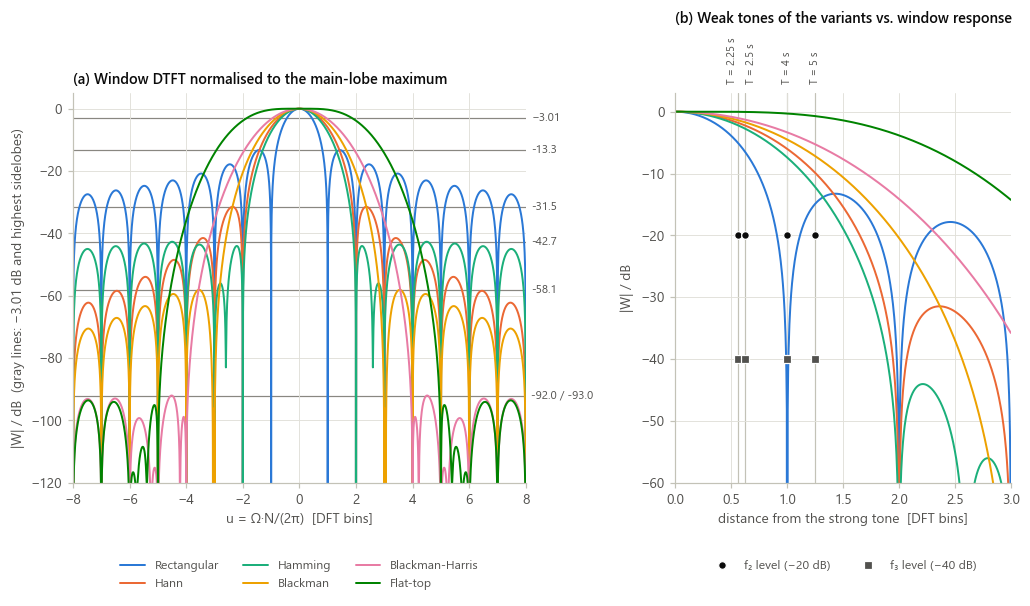

,coherent gain CG,CG [dB],ENBW [bins],3-dB BW [bins],6-dB BW [bins],main-lobe half-width (1st null) [bins],highest sidelobe [dB],scalloping loss [dB],coherent tone occupies [bins],Harris (1978): highest sidelobe [dB],Harris (1978): 6-dB BW [bins]
Rectangular,1.000,0.000,1.000,0.886,1.207,1.0,-13.261,3.922,1.0,-13.0,1.21
Hann,0.500,-6.021,1.500,1.441,2.000,2.0,-31.467,1.424,3.0,-32.0,2.00
Hamming,0.540,-5.352,1.363,1.303,1.815,2.0,-42.675,1.751,3.0,-43.0,1.81
Blackman,0.420,-7.535,1.727,1.644,2.299,3.0,-58.109,1.099,5.0,-58.0,2.35
Blackman-Harris,0.359,-8.904,2.004,1.899,2.666,4.0,-92.010,0.826,7.0,-92.0,2.72
Flat-top,0.216,-13.328,3.770,3.725,4.583,5.0,-93.022,0.010,9.0,NaN,NaN


Window response at the distances of the weak tones [dB] (exact value, not the ±0.5-bin worst case):


,Rectangular,Hann,Hamming,Blackman,Blackman-Harris,Flat-top
T = 2.25 s: 0.5625 bins,-5.1,-1.8,-2.2,-1.4,-1.0,-0.0
T = 2.5 s: 0.625 bins,-6.5,-2.2,-2.8,-1.7,-1.3,-0.0
T = 4 s: 1.0 bins,-300.0,-6.0,-7.4,-4.5,-3.3,-0.3
T = 5 s: 1.25 bins,-14.9,-9.9,-12.2,-7.2,-5.3,-0.7


In [9]:
WM = {name: WinMag(wf(N_w), P=256) for name, wf in WINDOWS.items()}
u_fine = np.arange(-8, 8 + 1e-9, 1/256)
OFFSETS = {"2.25 s": 0.5625, "2.5 s": 0.625, "4 s": 1.0, "5 s": 1.25}


def window_properties(w, P=256):
    N = w.size
    W = np.abs(fft(w, P*N))
    L = to_db(W/W[0])[: P*N//2]
    u = np.arange(L.size)/P
    i_null = next(i for i in range(1, L.size - 1) if L[i] <= L[i - 1] and L[i] <= L[i + 1])

    def half_width(level):
        i = int(np.argmax(L < level))
        return u[i - 1] + (level - L[i - 1])*(u[i] - u[i - 1])/(L[i] - L[i - 1])

    k = np.arange(N)
    Xc = np.abs(fft(np.sin(2*np.pi*400*k/N)*w))[: N//2]
    return {"coherent gain CG": w.mean(), "CG [dB]": 20*np.log10(w.mean()),
            "ENBW [bins]": N*np.sum(w**2)/np.sum(w)**2,
            "3-dB BW [bins]": 2*half_width(-3.0103), "6-dB BW [bins]": 2*half_width(-6.0206),
            "main-lobe half-width (1st null) [bins]": u[i_null],
            "highest sidelobe [dB]": L[i_null:].max(), "scalloping loss [dB]": -L[P//2],
            "coherent tone occupies [bins]": int(np.sum(to_db(Xc/Xc.max()) > -200))}


PROPS = pd.DataFrame({name: window_properties(wf(N_w)) for name, wf in WINDOWS.items()}).T
HARRIS = pd.DataFrame({"Harris (1978): highest sidelobe [dB]": [-13, -32, -43, -58, -92, np.nan],
                       "Harris (1978): 6-dB BW [bins]": [1.21, 2.00, 1.81, 2.35, 2.72, np.nan]},
                      index=list(WINDOWS))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.6), gridspec_kw={"width_ratios": [1.35, 1], "wspace": 0.38})
for name in WINDOWS:
    ax1.plot(u_fine, to_db(WM[name](u_fine)), color=WIN_COLORS[name], lw=1.3, label=name)
ax1.axhline(-3.01, color=MUTED, lw=0.8, zorder=0)
ax1.text(8.2, -3.01, "−3.01", va="center", fontsize=7.5, color=INK2, clip_on=False)
sl_levels = PROPS["highest sidelobe [dB]"]
for name, lvl in sl_levels.items():
    if name == "Flat-top":
        continue                     # -92.0 / -93.0 dB: one line for Blackman-Harris and flat-top
    ax1.axhline(lvl, color=MUTED, lw=0.8, zorder=0)
    lab = f"{lvl:.1f}" if name != "Blackman-Harris" else f"{lvl:.1f} / {sl_levels['Flat-top']:.1f}"
    ax1.text(8.2, lvl, lab, va="center", fontsize=7.5, color=INK2, clip_on=False)
ax1.set(xlim=(-8, 8), ylim=(-120, 5), xlabel="u = Ω·N/(2π)  [DFT bins]", ylabel="|W| / dB  (gray lines: −3.01 dB and highest sidelobes)")
ax1.set_title("(a) Window DTFT normalised to the main-lobe maximum")
ax1.legend(loc="upper center", ncol=3, bbox_to_anchor=(0.5, -0.17))

u_pos = np.arange(0, 3 + 1e-9, 1/256)
for name in WINDOWS:
    ax2.plot(u_pos, to_db(WM[name](u_pos)), color=WIN_COLORS[name], lw=1.3)
for (lab, off), ha in zip(OFFSETS.items(), ("right", "left", "center", "center")):
    ax2.axvline(off, color=AXIS, lw=0.8, zorder=0)
    ax2.text(off, 4.5, f"T = {lab}", rotation=90, fontsize=7, color=INK2, ha=ha, va="bottom", clip_on=False)
ax2.plot(list(OFFSETS.values()), [-20]*4, "o", color=INK, ms=5, mec="white", mew=0.8, label="f₂ level (−20 dB)")
ax2.plot(list(OFFSETS.values()), [-40]*4, "s", color=INK2, ms=5, mec="white", mew=0.8, label="f₃ level (−40 dB)")
ax2.set(xlim=(0, 3), ylim=(-60, 3), xlabel="distance from the strong tone  [DFT bins]", ylabel="|W| / dB")
ax2.set_title("(b) Weak tones of the variants vs. window response", pad=46)
ax2.legend(loc="upper center", ncol=2, bbox_to_anchor=(0.5, -0.17))
save(fig, "fig04_windows_dtft_zoom")

display(pd.concat([PROPS, HARRIS], axis=1).round(3))
resp = pd.DataFrame({name: [to_db(WM[name](np.array([off])))[0] for off in OFFSETS.values()] for name in WINDOWS},
                    index=[f"T = {lab}: {off} bins" for lab, off in OFFSETS.items()])
print("Window response at the distances of the weak tones [dB] (exact value, not the ±0.5-bin worst case):")
display(resp.round(1))

* The computed parameters agree with Harris (1978): highest sidelobe −13.3 / −31.5 / −42.7 / −58.1 / −92.0 dB
  and 6-dB bandwidth 1.21 / 2.00 / 1.81 / 2.30 / 2.67 bins for rectangular / Hann / Hamming / Blackman /
  Blackman–Harris (Harris rounds the sidelobes and quotes slightly larger widths for Blackman and
  Blackman–Harris); flat-top reaches −93.0 dB (−93.6 dB is drawn in Fig. 7 of the instructions).
* The main-lobe half-width grows from 1 bin (rectangular) to 2 (Hann, Hamming), 3 (Blackman), 4
  (Blackman–Harris) and 5 bins (flat-top), while the highest sidelobe falls from −13 dB to about −93 dB.
  The coherent gain falls from 0 dB to −13.3 dB (corrected in all further plots).
* A coherently sampled tone occupies exactly 2K − 1 DFT bins for a K-term cosine window: 1 (rectangular),
  3 (Hann, Hamming), 5 (Blackman), 7 (Blackman–Harris) and 9 (flat-top). This explains most of the DFT
  results in Sections 6–8.
* Panel (b): at the distances of the weak tones (0.5625–1.25 bins) every window responds between about −15 dB
  and 0 dB, i.e. above both weak-tone levels. Only the exact null of the rectangular window at 1 bin lets a
  weak tone through — and the DFT lands on that null only when the strong tone is coherently sampled.

## 6. Why do f₁, f₂ and f₃ look different although they are only 0.25 Hz apart?

Each tone of configuration C1 (variants 1, 5, 10) is analysed separately, in the style of Fig. 6 (each tone
normalised to its own amplitude, no coherent-gain correction). f₁ makes exactly 1500 periods in N = 2000
samples and lands on bin 500; f₂ and f₃ make 1501.25 and 1498.75 periods and land a quarter of a bin away
from the nearest bin (apparent bins 498.75 and 501.25).

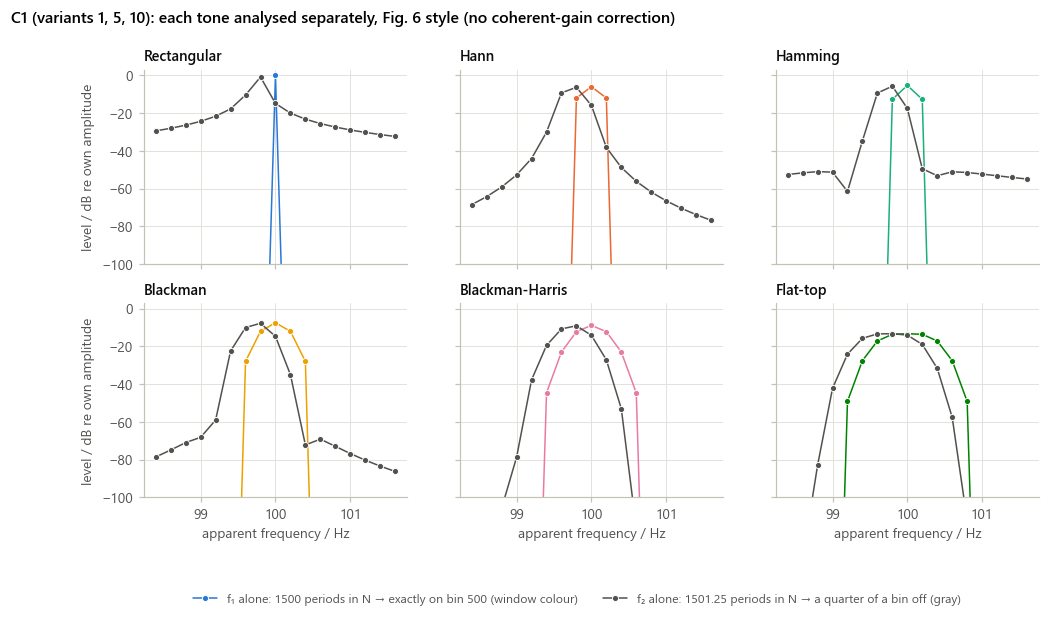

In [10]:
v1 = VARIANTS.loc[1]
fs1, N1 = float(v1.fs), int(v1.N)
A1_, f1_, c1_ = components(v1)
fa1 = alias(f1_[0], fs1)[0]
fk1 = np.arange(N1)*fs1/N1
mk1 = np.abs(fk1 - fa1) <= 8*fs1/N1 + 1e-9

fig, axs = plt.subplots(2, 3, figsize=(10.5, 5.4), sharex=True, sharey=True)
for ax, (name, wf) in zip(axs.flat, WINDOWS.items()):
    w = wf(N1)
    ax.plot(fk1[mk1], (fft2db(fft(c1_[0]*w)) - 20*np.log10(A1_[0]))[mk1], "o-", color=WIN_COLORS[name],
            ms=4, lw=1, mec="white", mew=0.6, label="f₁ alone (1500 periods → on bin 500)")
    ax.plot(fk1[mk1], (fft2db(fft(c1_[1]*w)) - 20*np.log10(A1_[1]))[mk1], "o-", color=INK2,
            ms=4, lw=1, mec="white", mew=0.6, label="f₂ alone (1501.25 periods → between bins)")
    ax.set_title(name)
    ax.set_ylim(-100, 3)
for ax in axs[-1]:
    ax.set_xlabel("apparent frequency / Hz")
for ax in axs[:, 0]:
    ax.set_ylabel("level / dB re own amplitude")
h, l = axs[0, 0].get_legend_handles_labels()
fig.legend(h, ["f₁ alone: 1500 periods in N → exactly on bin 500 (window colour)",
               "f₂ alone: 1501.25 periods in N → a quarter of a bin off (gray)"],
           loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.04))
fig.suptitle("C1 (variants 1, 5, 10): each tone analysed separately, Fig. 6 style (no coherent-gain correction)",
             x=0.01, ha="left")
fig.subplots_adjust(bottom=0.16)
save(fig, "fig05_tones_separately")

* **f₁ (coherent):** the rectangular window gives a single line, Hann and Hamming exactly 3 bins, Blackman 5,
  Blackman–Harris 7 and flat-top 9 bins; all other bins are at the numerical floor. The peak level equals the
  coherent gain (0, −6.0, −5.4, −7.5, −8.9, −13.3 dB).
* **f₂ (0.25 bin off; f₃ is its mirror image):** the bins sample the main lobe and the sidelobes of the window,
  so the tone loses up to 0.9 dB (rectangular, scalloping) and leaks into all bins — slowly decaying for the
  rectangular window (6 dB/octave), quickly for the tapered ones.
* **Coherence is fragile.** Shifting all three tones by only 0.1 bin (0.02 Hz in C1) removes the advantage of
  the coherent strong tone (table and figure below).

M1 = SLR of f2 / f3 on the DFT bins [dB] in C1 when all tones are shifted (detected if >= 6 dB):


,Rectangular,Hann,Hamming,Blackman,Blackman-Harris,Flat-top
shift 0.0 bin (0.00 Hz),39.1 / -0.9,59.5 / 19.5,60.0 / 23.8,-2.1 / -22.1,-7.8 / -27.7,-16.2 / -36.1
shift 0.1 bin (0.02 Hz),-1.4 / -20.2,11.6 / -7.4,17.7 / 1.9,-3.8 / -20.2,-8.8 / -26.7,-16.8 / -35.5
shift 0.25 bin (0.05 Hz),-6.1 / -25.5,2.7 / -30.2,7.6 / -27.8,-6.1 / -32.8,-10.2 / -34.6,-17.6 / -39.0
shift 0.5 bin (0.10 Hz),-7.5 / -27.7,-5.0 / -25.0,-1.5 / -21.5,-9.7 / -29.6,-12.5 / -32.5,-18.6 / -38.4


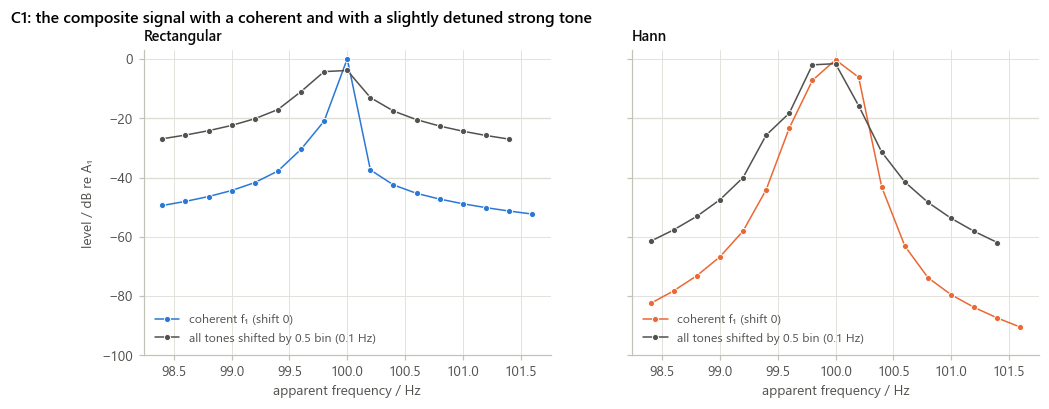

In [11]:
detune = {}
for d in (0.0, 0.1, 0.25, 0.5):
    A_, f_, c_ = components(v1, shift_bins=d)
    fa_ = [alias(x, fs1)[0] for x in f_]
    detune[f"shift {d} bin ({d*fs1/N1:.2f} Hz)"] = {
        name: f"{m1_slr(c_, 1, wf(N1), fa_[1], fs1):5.1f} / {m1_slr(c_, 2, wf(N1), fa_[2], fs1):5.1f}"
        for name, wf in WINDOWS.items()}
print("M1 = SLR of f2 / f3 on the DFT bins [dB] in C1 when all tones are shifted (detected if >= 6 dB):")
display(pd.DataFrame(detune).T)

fig, axs = plt.subplots(1, 2, figsize=(10.5, 3.6), sharey=True)
for ax, name in zip(axs, ["Rectangular", "Hann"]):
    w = WINDOWS[name](N1)
    for d, col, lab in ((0.0, WIN_COLORS[name], "coherent f₁ (shift 0)"),
                        (0.5, INK2, "all tones shifted by 0.5 bin (0.1 Hz)")):
        A_, f_, c_ = components(v1, shift_bins=d)
        fa0 = alias(f_[0], fs1)[0]
        m = np.abs(fk1 - fa0) <= 8*fs1/N1 + 1e-9
        ax.plot(fk1[m], level_re_A1(c_.sum(axis=0), w, A_[0])[m], "o-", color=col, ms=4, lw=1,
                mec="white", mew=0.6, label=lab)
    for lvl in (-20, -40):
        ax.axhline(lvl, color=AXIS, lw=0.8, zorder=0)
    ax.set(ylim=(-100, 3), xlabel="apparent frequency / Hz")
    ax.set_title(name)
    ax.legend(loc="lower left")
axs[0].set_ylabel("level / dB re A₁")
fig.suptitle("C1: the composite signal with a coherent and with a slightly detuned strong tone", x=0.01, ha="left")
save(fig, "fig06_detuning")

## 7. Spectra of the composite signal — all 15 variants

One figure per configuration; its title lists the variants it covers (results in dB re A₁ are identical for
them). **Markers:** DFT bins — the requested Fig. 6-type plot, level in dB re A₁ with coherent-gain correction.
**Thin line:** 32× zero-padded DFT (≈ DTFT). **Vertical lines:** apparent f₁, f₂, f₃ (order given in the
subtitle). **Horizontal lines:** expected weak-tone levels −20 dB and −40 dB. The note in each panel gives
metric M1 (✓ = the tone dominates one of its DFT bins by ≥ 6 dB).

In [12]:
SUB = str.maketrans("123", "₁₂₃")


def spectrum_panels(v, title, fname, N=None, half_span=10, pad=32, xlim=None, m3=False, m1=True):
    """2x3 panels (one per window): spectrum of the composite signal of variant v in dB re A1."""
    N = int(v.N) if N is None else int(N)
    fs = float(v.fs)
    A, f, comps = components(v, N=N)
    x = comps.sum(axis=0)
    fa = [alias(fi, fs)[0] for fi in f]
    dfr = fs/N
    fk, fz = np.arange(N)*dfr, np.arange(pad*N)*fs/(pad*N)
    lo, hi = xlim if xlim else (fa[0] - half_span*dfr, fa[0] + half_span*dfr)
    mk = (fk >= lo - 1e-9) & (fk <= hi + 1e-9)
    mz = (fz >= lo) & (fz <= hi)
    order = sorted(range(3), key=lambda i: fa[i])
    sub = " · ".join(f"f{str(i + 1).translate(SUB)} = {fa[i]:.2f} Hz" for i in order)
    fig, axs = plt.subplots(2, 3, figsize=(10.5, 5.9), sharex=True, sharey=True)
    for ax, (name, wf) in zip(axs.flat, WINDOWS.items()):
        w = wf(N)
        c = WIN_COLORS[name]
        ax.plot(fz[mz], zp_level_re_A1(x, w, A[0])[mz], color=c, lw=0.9, alpha=0.4,
                label="zero-padded DFT (≈ DTFT)")
        ax.plot(fk[mk], level_re_A1(x, w, A[0])[mk], "o-", color=c, lw=0.9, ms=4, mec="white", mew=0.6,
                label="DFT bins")
        for lvl in (-20, -40):
            ax.axhline(lvl, color=AXIS, lw=0.8, zorder=0)
        for fi in fa:
            ax.axvline(fi, color=AXIS, lw=0.8, zorder=0)
        ax.set_title(name)
        ax.set_xlim(lo, hi)
        ax.set_ylim(-100, 5)
        if not m1:
            continue
        s2, s3 = m1_slr(comps, 1, w, fa[1], fs), m1_slr(comps, 2, w, fa[2], fs)
        val = lambda s: "≥60" if s >= SLR_CAP else f"{s:.0f}"
        note = (f"DFT (M1):  f₂ {'✓' if s2 >= DETECT_DB else '✗'} {val(s2)} dB · "
                f"f₃ {'✓' if s3 >= DETECT_DB else '✗'} {val(s3)} dB")
        if m3:
            r2, r3 = (m3_resolved(A, f, fs, N, i, w) for i in (1, 2))
            note += f"\nseparated (M3):  f₂ {'✓' if r2 else '✗'} · f₃ {'✓' if r3 else '✗'}"
        ax.text(0.02, 0.03, note, transform=ax.transAxes, fontsize=7.2, color=INK2, va="bottom",
                bbox=dict(facecolor="white", edgecolor="none", alpha=0.85, pad=1.5))
    for ax in axs[-1]:
        ax.set_xlabel("apparent frequency / Hz")
    for ax in axs[:, 0]:
        ax.set_ylabel("level / dB re A₁")
    proxies = [Line2D([], [], color=INK2, lw=0.9, alpha=0.4),
               Line2D([], [], color=INK2, lw=0.9, marker="o", ms=4, mec="white", mew=0.6)]
    fig.legend(proxies, ["32× zero-padded DFT (≈ DTFT)", "DFT bins (colour = window)"], loc="lower center",
               ncol=2, bbox_to_anchor=(0.5, -0.01))
    fig.suptitle(title, x=0.01, ha="left")
    fig.text(0.01, 0.935, f"vertical lines (left → right): {sub};  horizontal: −20 dB (A₂), −40 dB (A₃)",
             fontsize=8, color=INK2)
    fig.subplots_adjust(top=0.86, bottom=0.15)
    save(fig, fname)


def config_title(cfg):
    d = DERIVED.loc[cfg]
    v = VARIANTS.loc[CONFIGS[cfg][0]]
    many = len(CONFIGS[cfg]) > 1
    sp = float(d["spacing [bins]"])
    return (f"{cfg} — variant{'s' if many else ''} {d['variants']}:  f₁ = {v.f1:g} Hz, fₛ = {d['fs [Hz]']:g} Hz, "
            f"N = {d['N']}, T = {d['T = N/fs [s]']:g} s, spacing {sp:g} bin{'' if sp == 1 else 's'}")

### 7.1 C1 — variants 1, 5, 10 (T = 5 s, spacing 1.25 bins)

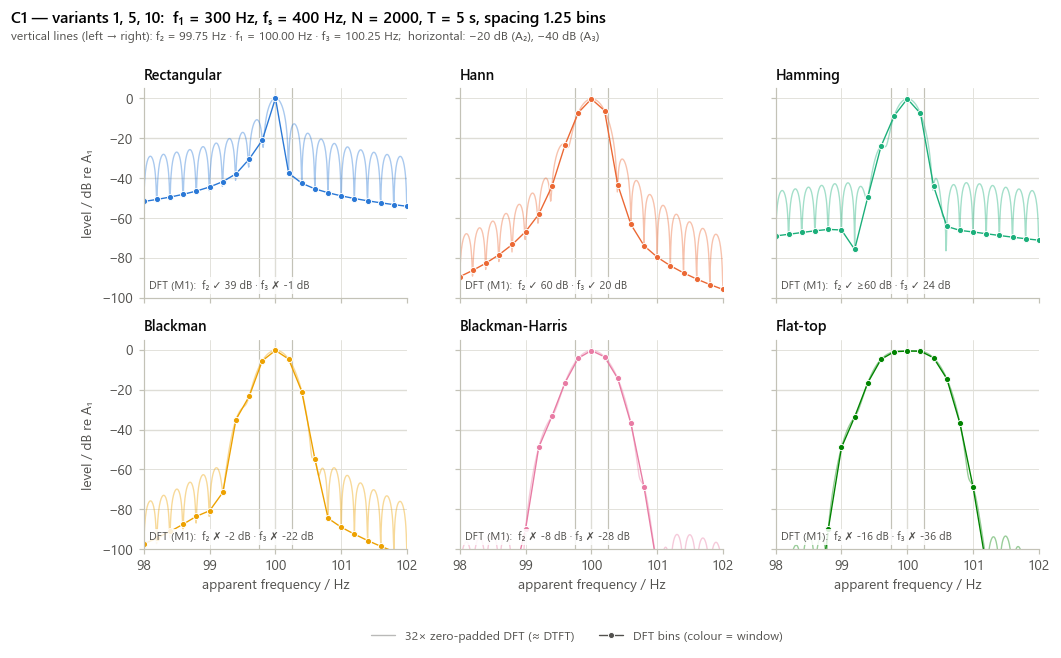

In [13]:
spectrum_panels(VARIANTS.loc[1], config_title("C1"), "fig07_C1")

Rectangular: f₂ appears on bins 498/499 (SLR 39 dB) because the coherent f₁ contributes nothing outside its own
bin; f₃ is buried under the slowly decaying leakage of f₂. Hann and Hamming: f₁ occupies only bins 499–501, so
bin 498 shows f₂ and bin 502 shows f₃ — both weak tones are visible as shoulders of the strong line.
Blackman, Blackman–Harris and flat-top: the 5–9 bins of f₁ cover both weak tones. In the zero-padded curves
no window produces a separate peak.

### 7.2 C2 — variants 2, 7, 12 (T = 5 s, spacing 1.25 bins)

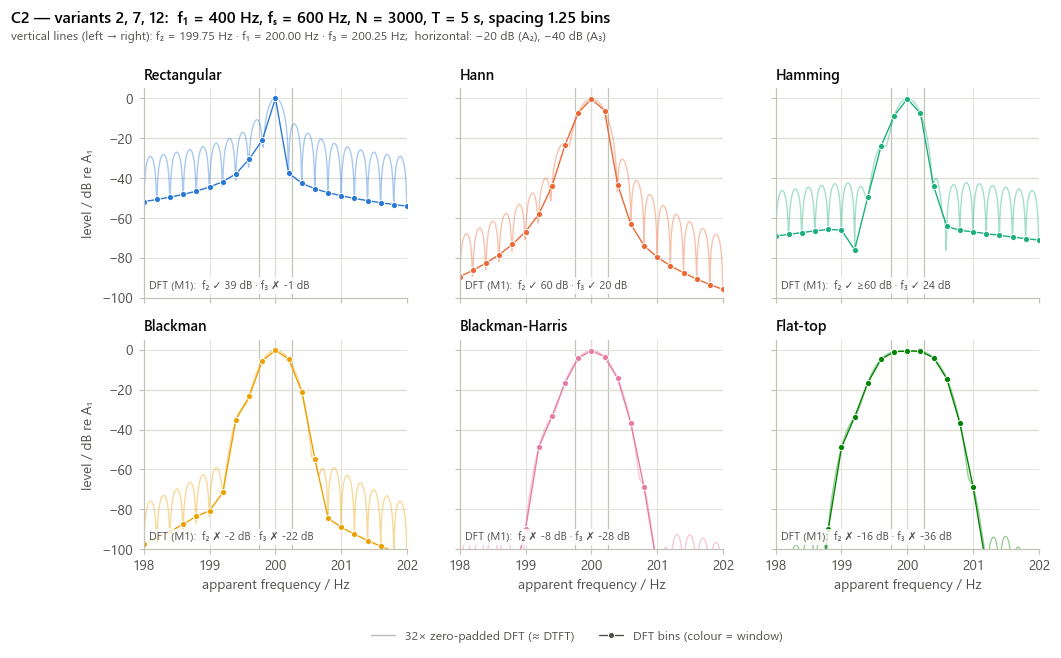

In [14]:
spectrum_panels(VARIANTS.loc[2], config_title("C2"), "fig08_C2")

Same geometry as C1 (T = 5 s, f₁ on a bin, weak tones 1.25 bins away), only at 200 Hz apparent frequency:
identical results.

### 7.3 C3 — variants 3, 8, 13 (T = 2.25 s, spacing 0.5625 bins)

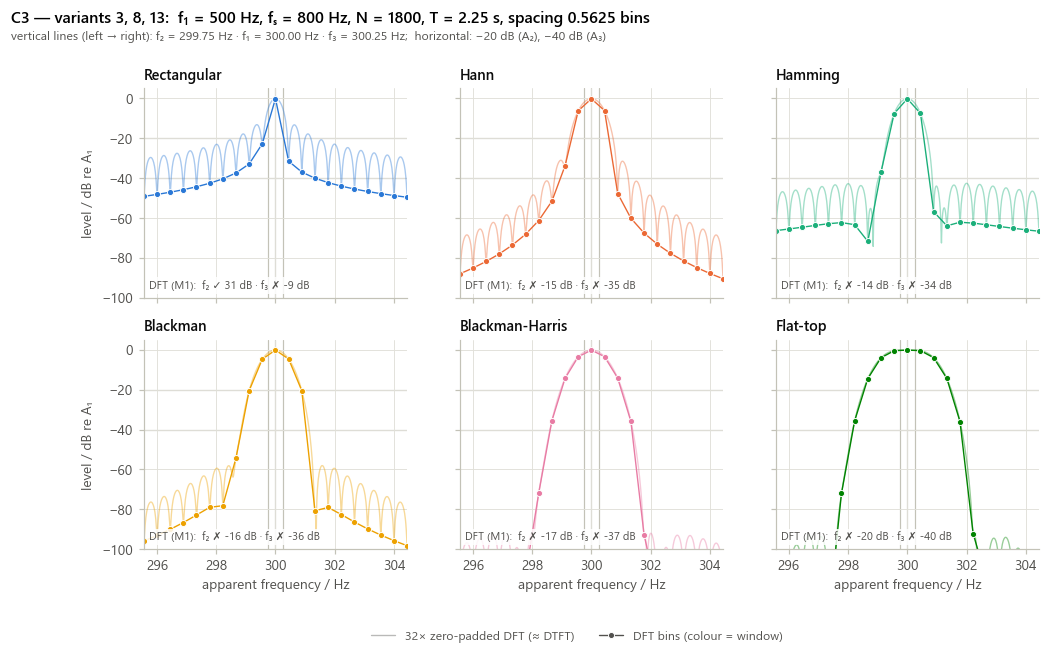

In [15]:
spectrum_panels(VARIANTS.loc[3], config_title("C3"), "fig09_C3")

The weak tones are less than one bin from f₁. Only the rectangular window shows f₂ (on bin 674, thanks to the
coherent f₁); f₃ is hidden for every window.

### 7.4 C4 — variants 4, 9, 14 (T = 4 s, spacing exactly 1 bin)

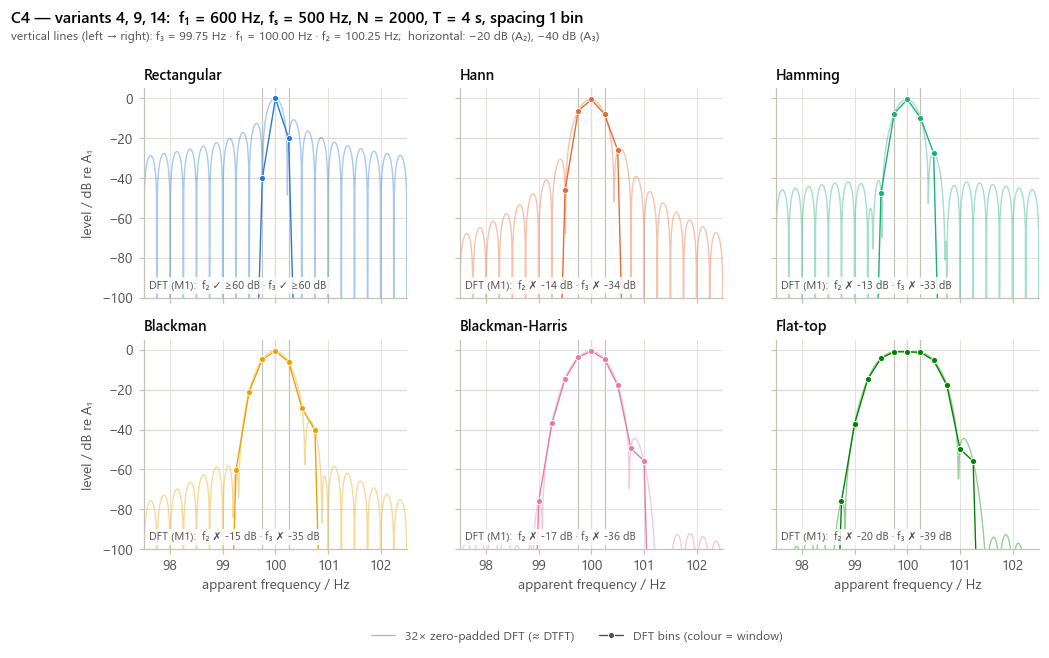

In [16]:
spectrum_panels(VARIANTS.loc[4], config_title("C4"), "fig10_C4")

All three tones are coherent and exactly one bin apart, and the alias is not mirrored (f₂ lies above f₁).
Rectangular: three clean lines at 0, −20 and −40 dB, every other bin at the numerical floor — perfect detection.
Every tapered window spreads f₁ over at least bins ±1, which is exactly where the weak tones are.

### 7.5 C5 — variant 6 (T = 2.5 s, spacing 0.625 bins)

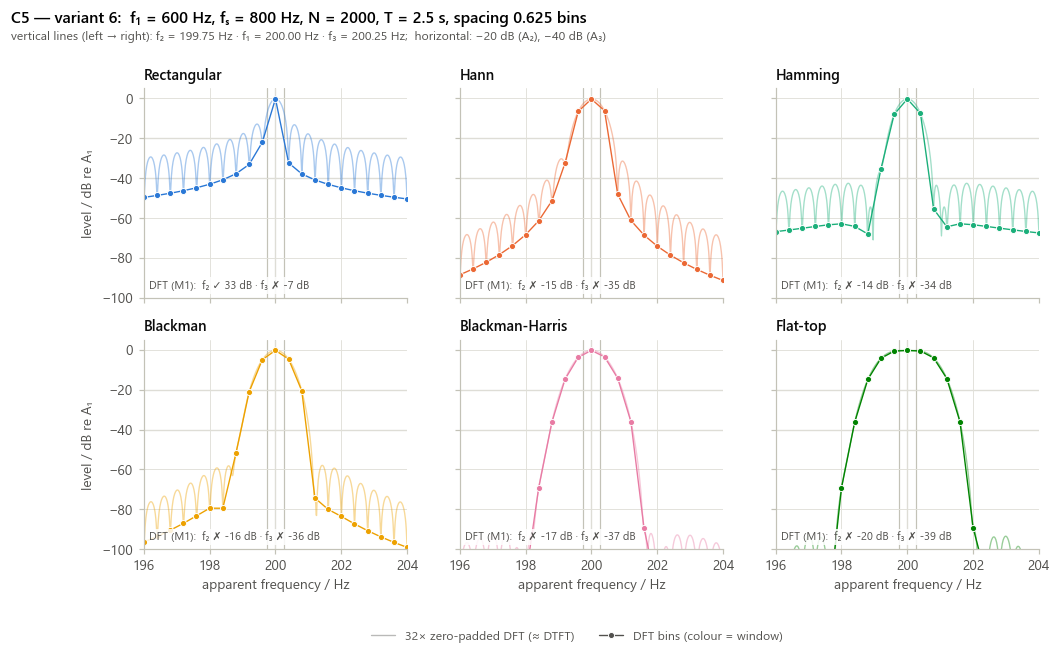

In [17]:
spectrum_panels(VARIANTS.loc[6], config_title("C5"), "fig11_C5")

Like C3: only the rectangular window shows f₂; f₃ is hidden for every window.

### 7.6 C6 — variant 11 (degenerate: f₁ = fₛ/2)

The plot ends at fₛ/2 = 200 Hz (bin N/2, which `fft2db` does not double). Only one tone exists in the samples:
f₂ and f₃ both appear at 199.75 Hz and add up to a sine of amplitude 0.09·A₁ (−20.9 dB re A₁); f₁ = 200 Hz is
sampled at its zero crossings and produces nothing. The image of the tone at 200.25 Hz lies 2.5 bins away,
just beyond fₛ/2.

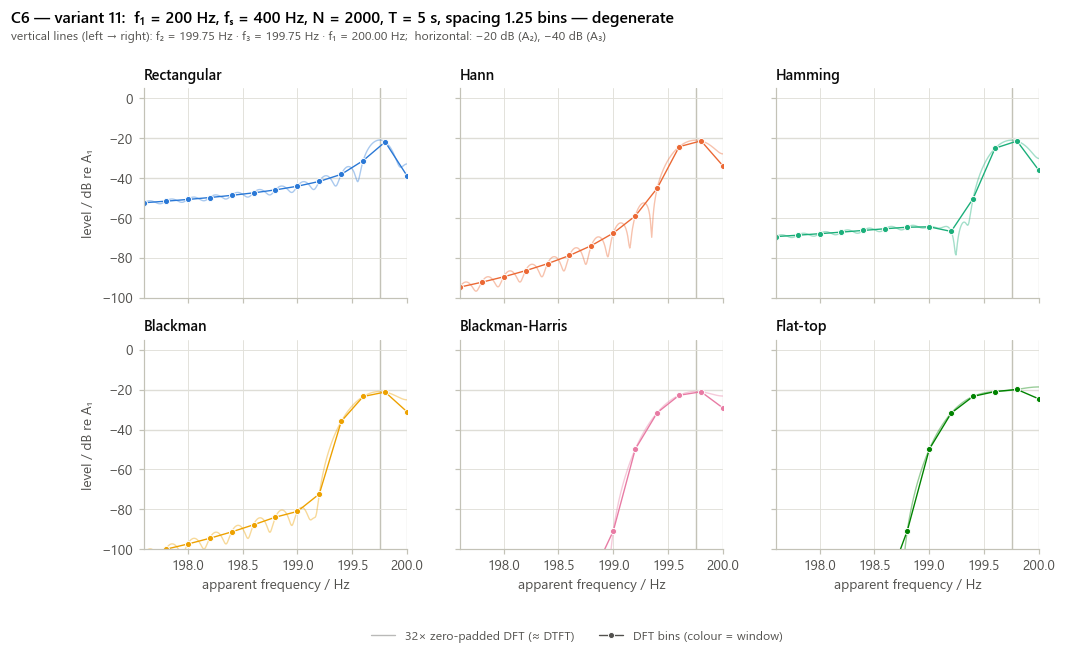

In [18]:
spectrum_panels(VARIANTS.loc[11], config_title("C6") + " — degenerate", "fig12_C6_V11",
                xlim=(200 - 12*400/2000, 200), m1=False)

Every window shows the same single tone at 199.75 Hz (−20.9 dB re A₁). No window can recover A₁, A₂ or A₃ here:
the information was lost at sampling, not at windowing, so variant 11 is excluded from the comparison in Section 8.

### 7.7 C7 — variant 15 (T = 2.5 s, spacing 0.625 bins)

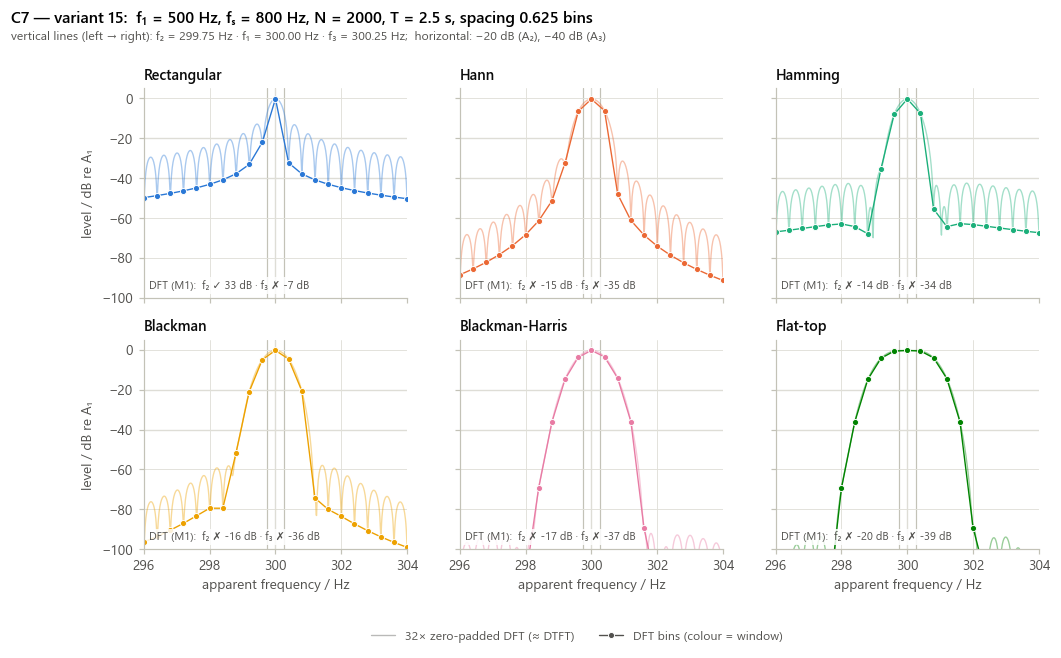

In [19]:
spectrum_panels(VARIANTS.loc[15], config_title("C7"), "fig13_C7")

Same geometry as C5 (only the apparent frequency differs: 300 Hz): only the rectangular window shows f₂.

## 8. Comparison of the windows across all 15 variants

The metrics are computed for every variant (15) and window (6). Variant 11 is excluded (degenerate).

In [20]:
recs = []
for no, v in VARIANTS.iterrows():
    if no == 11:
        continue
    fs, N = float(v.fs), int(v.N)
    A, f, comps = components(v)
    fa = [alias(x, fs)[0] for x in f]
    r = A/A[0]
    for name, wf in WINDOWS.items():
        w = wf(N)
        wm = WinMag(w)
        rec = {"No": no, "config": CONFIG[no], "window": name}
        for i, tag in ((1, "f2"), (2, "f3")):
            rec[f"M1 {tag}"] = m1_slr(comps, i, w, fa[i], fs)
            rec[f"M2 {tag}"] = m2_detectability(wm, fa, r, i, fs, N)
            rec[f"M3 {tag}"] = m3_resolved(A, f, fs, N, i, w)
        recs.append(rec)
MET = pd.DataFrame(recs)

# identical results within each configuration (A1 only shifts the dB scale)
for cfg, nos in CONFIGS.items():
    if cfg == "C6":
        continue
    block = [MET[MET.No == no].drop(columns=["No"]).reset_index(drop=True) for no in nos]
    for b in block[1:]:
        pd.testing.assert_frame_equal(block[0], b, atol=1e-6)
print("Identical metrics within every configuration: OK")


def pair(df, a, b, fmt="{:.1f}"):
    """'f2 / f3' strings, with capped M1 values shown as ≥60."""
    def one(x):
        if isinstance(x, (bool, np.bool_)):
            return "✓" if x else "✗"
        return "≥60" if x >= SLR_CAP else fmt.format(x)
    return df[a].map(one) + " / " + df[b].map(one)


rows_order = [no for cfg in CONFIGS for no in CONFIGS[cfg] if no != 11]
lab = {no: f"V{no} ({CONFIG[no]})" for no in VARIANTS.index}
M1_TAB = (MET.assign(cell=pair(MET, "M1 f2", "M1 f3"))
             .pivot(index="No", columns="window", values="cell").loc[rows_order, list(WINDOWS)]
             .rename(index=lab))
print("M1 – SLR of f2 / f3 on the DFT bins [dB] (detected if >= 6 dB):")
display(M1_TAB)

Identical metrics within every configuration: OK
M1 – SLR of f2 / f3 on the DFT bins [dB] (detected if >= 6 dB):


window,Rectangular,Hann,Hamming,Blackman,Blackman-Harris,Flat-top
No,,,,,,
V1 (C1),39.1 / -0.9,59.5 / 19.5,≥60 / 23.8,-2.1 / -22.1,-7.8 / -27.7,-16.2 / -36.1
V5 (C1),39.1 / -0.9,59.5 / 19.5,≥60 / 23.8,-2.1 / -22.1,-7.8 / -27.7,-16.2 / -36.1
V10 (C1),39.1 / -0.9,59.5 / 19.5,≥60 / 23.8,-2.1 / -22.1,-7.8 / -27.7,-16.2 / -36.1
V2 (C2),39.1 / -0.9,59.5 / 19.5,≥60 / 23.8,-2.1 / -22.1,-7.8 / -27.7,-16.2 / -36.1
V7 (C2),39.1 / -0.9,59.5 / 19.5,≥60 / 23.8,-2.1 / -22.1,-7.8 / -27.7,-16.2 / -36.1
V12 (C2),39.1 / -0.9,59.5 / 19.5,≥60 / 23.8,-2.1 / -22.1,-7.8 / -27.7,-16.2 / -36.1
V3 (C3),31.1 / -9.0,-15.1 / -35.0,-13.9 / -33.9,-16.3 / -36.3,-17.3 / -37.2,-19.7 / -39.6
V8 (C3),31.1 / -9.0,-15.1 / -35.0,-13.9 / -33.9,-16.3 / -36.3,-17.3 / -37.2,-19.7 / -39.6
V13 (C3),31.1 / -9.0,-15.1 / -35.0,-13.9 / -33.9,-16.3 / -36.3,-17.3 / -37.2,-19.7 / -39.6


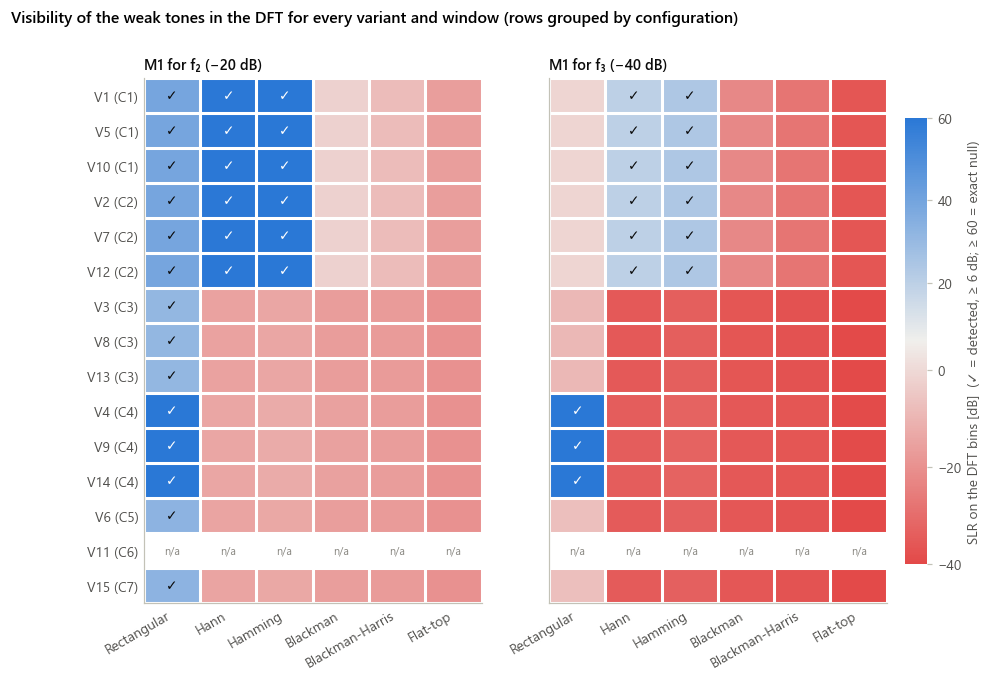

In [21]:
fig, axs = plt.subplots(1, 2, figsize=(10.5, 6.2), sharey=True)
cmap = LinearSegmentedColormap.from_list("detect", ["#e34948", "#f0efec", "#2a78d6"])
cmap.set_bad("white")
norm = TwoSlopeNorm(vmin=-40, vcenter=DETECT_DB, vmax=SLR_CAP)
all_rows = [no for cfg in CONFIGS for no in CONFIGS[cfg]]
for ax, tag, ttl in zip(axs, ("f2", "f3"), ("f₂ (−20 dB)", "f₃ (−40 dB)")):
    data = np.full((len(all_rows), len(WINDOWS)), np.nan)
    for a, no in enumerate(all_rows):
        for b, name in enumerate(WINDOWS):
            sel = MET[(MET.No == no) & (MET.window == name)]
            if len(sel):
                data[a, b] = sel[f"M1 {tag}"].iloc[0]
    im = ax.imshow(np.clip(data, -40, SLR_CAP), cmap=cmap, norm=norm, aspect="auto")
    for a in range(data.shape[0]):
        for b in range(data.shape[1]):
            val = data[a, b]
            if np.isnan(val):
                ax.text(b, a, "n/a", ha="center", va="center", fontsize=7, color=MUTED)
            elif val >= DETECT_DB:
                rgb = cmap(norm(min(val, SLR_CAP)))[:3]
                lum = 0.2126*rgb[0] + 0.7152*rgb[1] + 0.0722*rgb[2]
                ax.text(b, a, "✓", ha="center", va="center", fontsize=9, color="white" if lum < 0.5 else INK)
    ax.set_xticks(range(len(WINDOWS)), list(WINDOWS), rotation=30, ha="right")
    ax.set_yticks(range(len(all_rows)), [lab[no] for no in all_rows])
    ax.set_xticks(np.arange(-0.5, len(WINDOWS)), minor=True)
    ax.set_yticks(np.arange(-0.5, len(all_rows)), minor=True)
    ax.grid(False)
    ax.grid(which="minor", color="white", lw=2)
    ax.tick_params(which="both", length=0)
    ax.set_title(f"M1 for {ttl}")
cb = fig.colorbar(im, ax=axs, shrink=0.85, pad=0.02)
cb.set_label("SLR on the DFT bins [dB]  (✓ = detected, ≥ 6 dB; ≥ 60 = exact null)")
cb.outline.set_visible(False)
fig.suptitle("Visibility of the weak tones in the DFT for every variant and window (rows grouped by configuration)",
             x=0.01, ha="left")
save(fig, "fig14_heatmap_M1")

In [22]:
summary = []
for no in all_rows:
    if no == 11:
        summary.append({"variant": lab[no], "T [s]": VARIANTS.loc[no].N/VARIANTS.loc[no].fs,
                        "f₂ visible in DFT (M1)": "n/a", "f₃ visible in DFT (M1)": "n/a",
                        "best window (DFT)": "n/a — f₁ not sampled, f₂ ≡ f₃",
                        "separable by any window (M2/M3)": "n/a"})
        continue
    sel = MET[MET.No == no].set_index("window")
    d2 = [w for w in WINDOWS if sel.loc[w, "M1 f2"] >= DETECT_DB]
    d3 = [w for w in WINDOWS if sel.loc[w, "M1 f3"] >= DETECT_DB]
    count = {w: (w in d2) + (w in d3) for w in WINDOWS}
    best = max(count.values())
    best_w = sorted([w for w in WINDOWS if count[w] == best], key=lambda w: -sel.loc[w, "M1 f3"])
    intrinsic = (sel[["M2 f2", "M2 f3"]] >= DETECT_DB).any().any() or sel[["M3 f2", "M3 f3"]].any().any()
    summary.append({"variant": lab[no], "T [s]": VARIANTS.loc[no].N/VARIANTS.loc[no].fs,
                    "f₂ visible in DFT (M1)": ", ".join(d2) or "—", "f₃ visible in DFT (M1)": ", ".join(d3) or "—",
                    "best window (DFT)": ", ".join(best_w) if best else "—",
                    "separable by any window (M2/M3)": "yes" if intrinsic else "no"})
SUMMARY = pd.DataFrame(summary).set_index("variant")
display(SUMMARY)

first = {cfg: nos[0] for cfg, nos in CONFIGS.items() if cfg != "C6"}
M2_TAB = (MET[MET.No.isin(first.values())].assign(cell=pair(MET, "M2 f2", "M2 f3"))
          .pivot(index="config", columns="window", values="cell")[list(WINDOWS)])
M3_TAB = (MET[MET.No.isin(first.values())].assign(cell=pair(MET, "M3 f2", "M3 f3"))
          .pivot(index="config", columns="window", values="cell")[list(WINDOWS)])
print("M2 – grid-independent detectability D of f2 / f3 [dB] per configuration (detectable if >= 6 dB):")
display(M2_TAB)
print("M3 – separated in the zero-padded spectrum (f2 / f3), worst case over 16 phases:")
display(M3_TAB)

,T [s],f₂ visible in DFT (M1),f₃ visible in DFT (M1),best window (DFT),separable by any window (M2/M3)
variant,,,,,
V1 (C1),5.00,"Rectangular, Hann, Hamming","Hann, Hamming","Hamming, Hann",no
V5 (C1),5.00,"Rectangular, Hann, Hamming","Hann, Hamming","Hamming, Hann",no
V10 (C1),5.00,"Rectangular, Hann, Hamming","Hann, Hamming","Hamming, Hann",no
V2 (C2),5.00,"Rectangular, Hann, Hamming","Hann, Hamming","Hamming, Hann",no
V7 (C2),5.00,"Rectangular, Hann, Hamming","Hann, Hamming","Hamming, Hann",no
V12 (C2),5.00,"Rectangular, Hann, Hamming","Hann, Hamming","Hamming, Hann",no
V3 (C3),2.25,Rectangular,—,Rectangular,no
V8 (C3),2.25,Rectangular,—,Rectangular,no
V13 (C3),2.25,Rectangular,—,Rectangular,no


M2 – grid-independent detectability D of f2 / f3 [dB] per configuration (detectable if >= 6 dB):


window,Rectangular,Hann,Hamming,Blackman,Blackman-Harris,Flat-top
config,,,,,,
C1,-9.6 / -29.6,-16.7 / -36.7,-16.0 / -36.0,-17.5 / -37.6,-18.2 / -38.3,-20.0 / -40.5
C2,-9.6 / -29.6,-16.7 / -36.7,-16.0 / -36.0,-17.5 / -37.6,-18.2 / -38.3,-20.0 / -40.5
C3,-20.0 / -40.3,-20.0 / -40.6,-20.0 / -40.6,-20.1 / -40.7,-20.1 / -40.7,-20.1 / -40.8
C4,-16.1 / -36.4,-18.6 / -38.7,-18.3 / -38.4,-18.9 / -39.2,-19.2 / -39.6,-20.1 / -40.7
C5,-19.8 / -40.0,-20.0 / -40.5,-19.9 / -40.4,-20.0 / -40.6,-20.0 / -40.6,-20.1 / -40.8
C7,-19.8 / -40.0,-20.0 / -40.5,-19.9 / -40.4,-20.0 / -40.6,-20.0 / -40.6,-20.1 / -40.8


M3 – separated in the zero-padded spectrum (f2 / f3), worst case over 16 phases:


window,Rectangular,Hann,Hamming,Blackman,Blackman-Harris,Flat-top
config,,,,,,
C1,✗ / ✗,✗ / ✗,✗ / ✗,✗ / ✗,✗ / ✗,✗ / ✗
C2,✗ / ✗,✗ / ✗,✗ / ✗,✗ / ✗,✗ / ✗,✗ / ✗
C3,✗ / ✗,✗ / ✗,✗ / ✗,✗ / ✗,✗ / ✗,✗ / ✗
C4,✗ / ✗,✗ / ✗,✗ / ✗,✗ / ✗,✗ / ✗,✗ / ✗
C5,✗ / ✗,✗ / ✗,✗ / ✗,✗ / ✗,✗ / ✗,✗ / ✗
C7,✗ / ✗,✗ / ✗,✗ / ✗,✗ / ✗,✗ / ✗,✗ / ✗


In [23]:
# Checks of the statements made in the text
det = {cfg: ({w for w in WINDOWS if MET[(MET.No == no) & (MET.window == w)]["M1 f2"].iloc[0] >= DETECT_DB},
             {w for w in WINDOWS if MET[(MET.No == no) & (MET.window == w)]["M1 f3"].iloc[0] >= DETECT_DB})
       for cfg, no in first.items()}
assert det["C1"] == det["C2"] == ({"Rectangular", "Hann", "Hamming"}, {"Hann", "Hamming"})
assert det["C4"] == ({"Rectangular"}, {"Rectangular"})
assert det["C3"] == det["C5"] == det["C7"] == ({"Rectangular"}, set())
assert (MET[["M2 f2", "M2 f3"]] < DETECT_DB).all().all() and not MET[["M3 f2", "M3 f3"]].any().any()
print(f"Best grid-independent value over all variants and windows: M2 = {MET[['M2 f2', 'M2 f3']].max().max():.1f} dB"
      " -> no window can detect a weak tone in any variant without the help of coherent sampling.")

Best grid-independent value over all variants and windows: M2 = -9.6 dB -> no window can detect a weak tone in any variant without the help of coherent sampling.


**Results across the variants**

* **DFT view (M1, what the requested plot shows).** In the six variants with T = 5 s (1, 2, 5, 7, 10, 12) the
  best windows are **Hamming and Hann**: both weak tones dominate a bin of their own (SLR of f₂ / f₃: ≥ 60 / 23.8 dB with Hamming, 59.5 / 19.5 dB
  with Hann).
  The rectangular window shows only f₂. In the three variants with T = 4 s (4, 9, 14) the **rectangular** window
  is perfect (all tones coherent, three clean lines) and all other windows hide both weak tones. In the five
  variants with T = 2.25–2.5 s (3, 6, 8, 13, 15) only the **rectangular** window shows f₂, and no window shows f₃.
  Blackman, Blackman–Harris and flat-top never show a weak tone in these short records.
* **Window-intrinsic view (M2, M3).** No window detects or separates f₂ or f₃ in any variant (best M2 value
  −9.6 dB; no separation). Every DFT detection above exists only because f₁ is coherently sampled, and it
  disappears for a frequency error of 0.1–0.25 bin (Section 6).
* **Variant 11** cannot be analysed for weak tones: f₁ is not in the samples and f₂, f₃ coincide after aliasing.

## 9. Where is which window better? General comparison

To answer this independently of the very short, coherently sampled records of Table 1, a strong tone and a weak
tone at level L (0 … −80 dB re the strong tone) and spacing Δ (0.25 … 40 bins) are analysed with each window
using metric M3 on the window DTFT (worst case over 16 relative phases). The DTFT is shift-invariant, so the
fractional bin position does not matter. The result is the minimum spacing Δₘᵢₙ from which the weak tone is
separated for all larger spacings. Since Δ = Δf·T, the required observation time for the 0.25 Hz spacing of
the task is Tₘᵢₙ = Δₘᵢₙ / 0.25 Hz.

In [24]:
def sweep_min_spacing(levels_db, spacings, N=2000, P=32):
    ph = PHASES[:, None]
    i0 = 2*P
    out = {}
    for name, wf in WINDOWS.items():
        Wc = fft(wf(N), P*N)
        M = P*N
        dmin = []
        for ldb in levels_db:
            r = 10**(ldb/20)
            ok = []
            for D in spacings:
                m = np.arange(-2*P, int(round((D + 2)*P)) + 1)
                Ws, Ww = Wc[m % M], Wc[(m - int(round(D*P))) % M]
                S = to_db(Ws[None, :] + r*np.exp(1j*ph)*Ww[None, :])
                R = np.broadcast_to(to_db(Ws), S.shape)
                i_lo, i_hi = i0 + int(np.ceil((D - 0.5)*P)), i0 + int(np.floor((D + 0.5)*P))
                ok.append(bool(_resolved(S, R, i_lo, i_hi, i0).all()))
            ok = np.array(ok)
            idx = len(ok) - 1
            if not ok[idx]:
                dmin.append(np.inf)
                continue
            while idx > 0 and ok[idx - 1]:
                idx -= 1
            dmin.append(float(spacings[idx]))
        out[name] = dmin
    return pd.DataFrame(out, index=pd.Index(levels_db, name="weak tone [dB re strong]"))


LEVELS = [0, -10, -20, -30, -40, -50, -60, -70, -80]
SPACINGS = np.arange(0.25, 40 + 1e-9, 0.125)
DMIN = sweep_min_spacing(LEVELS, SPACINGS)
best_per_level = DMIN.apply(lambda row: ", ".join(row.index[row == row.min()]), axis=1)
print("Minimum spacing Δmin [bins] for separation (inf = not within 40 bins):")
display(DMIN.assign(**{"best window": best_per_level}))

Minimum spacing Δmin [bins] for separation (inf = not within 40 bins):


,Rectangular,Hann,Hamming,Blackman,Blackman-Harris,Flat-top,best window
weak tone [dB re strong],,,,,,,
0,1.625,2.500,2.250,2.875,3.250,5.250,Rectangular
-10,2.625,2.750,2.625,3.375,3.875,5.875,"Rectangular, Hamming"
-20,8.625,2.750,2.750,3.625,4.250,6.250,"Hann, Hamming"
-30,28.625,3.250,2.750,3.750,4.625,6.500,Hamming
-40,inf,4.250,9.625,3.750,4.750,6.750,Blackman
-50,inf,6.125,32.625,3.750,4.875,6.875,Blackman
-60,inf,8.750,inf,6.250,5.000,6.875,Blackman-Harris
-70,inf,12.750,inf,9.625,5.000,6.875,Blackman-Harris
-80,inf,18.625,inf,13.625,5.000,6.875,Blackman-Harris


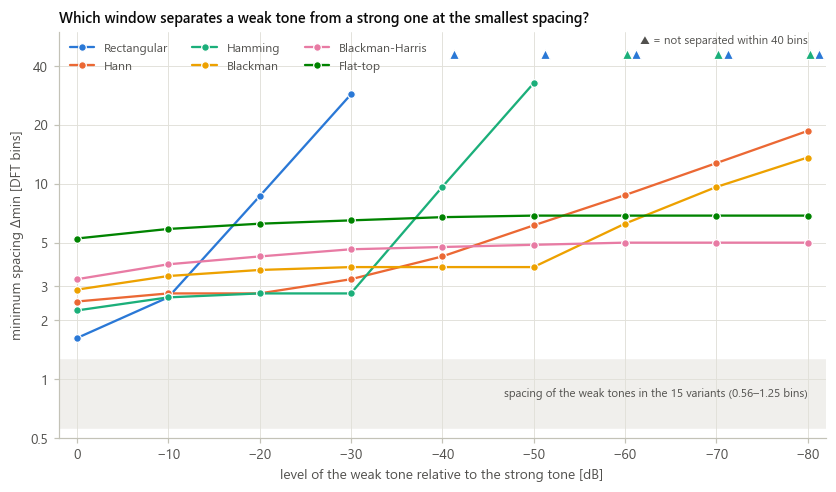

In [25]:
fig, ax = plt.subplots(figsize=(9, 4.8))
TOP = 46
for j, name in enumerate(WINDOWS):
    y = DMIN[name].replace(np.inf, np.nan)
    ax.plot(LEVELS, y, "o-", color=WIN_COLORS[name], ms=5, lw=1.5, mec="white", mew=0.8, label=name)
    inf_lv = [lv for lv, d in zip(LEVELS, DMIN[name]) if np.isinf(d)]
    if inf_lv:
        ax.plot(np.array(inf_lv) + (j - 2.5)*0.5, [TOP]*len(inf_lv), "^", color=WIN_COLORS[name], ms=6,
                mec="white", mew=0.8)
ax.axhspan(0.5625, 1.25, color="#f0efec", zorder=0)
ax.text(-80, 0.85, "spacing of the weak tones in the 15 variants (0.56–1.25 bins)", fontsize=7.5, color=INK2,
        va="center", ha="right")
ax.text(-80, TOP*1.18, "▲ = not separated within 40 bins", fontsize=7.5, color=INK2, va="center", ha="right")
ax.set_yscale("log")
ax.set_ylim(0.5, 60)
ax.yaxis.set_major_locator(FixedLocator([0.5, 1, 2, 3, 5, 10, 20, 40]))
ax.yaxis.set_major_formatter(FixedFormatter(["0.5", "1", "2", "3", "5", "10", "20", "40"]))
ax.yaxis.set_minor_locator(FixedLocator([]))
ax.set_xlim(2, -82)
ax.set_xticks(LEVELS)
ax.set_xlabel("level of the weak tone relative to the strong tone [dB]")
ax.set_ylabel("minimum spacing Δmin [DFT bins]")
ax.set_title("Which window separates a weak tone from a strong one at the smallest spacing?")
ax.legend(loc="upper left", ncol=3)
save(fig, "fig15_sweep_min_spacing")

In [26]:
SPACING_HZ = 0.25
need = pd.DataFrame({"Δmin f₂ (−20 dB) [bins]": DMIN.loc[-20], "Δmin f₃ (−40 dB) [bins]": DMIN.loc[-40]})
need["Tmin for both [s]"] = need.max(axis=1)/SPACING_HZ
for fs in (400, 500, 600, 800):
    need[f"Nmin @ fs={fs} Hz"] = need["Tmin for both [s]"].map(lambda t: "—" if np.isinf(t) else f"{int(np.ceil(t*fs))}")
need["Tmin for both [s]"] = need["Tmin for both [s]"].map(lambda t: "—" if np.isinf(t) else f"{t:g}")
print("Observation time needed to separate both weak tones of the task (0.25 Hz spacing):")
display(need)

Observation time needed to separate both weak tones of the task (0.25 Hz spacing):


,Δmin f₂ (−20 dB) [bins],Δmin f₃ (−40 dB) [bins],Tmin for both [s],Nmin @ fs=400 Hz,Nmin @ fs=500 Hz,Nmin @ fs=600 Hz,Nmin @ fs=800 Hz
Rectangular,8.625,inf,—,—,—,—,—
Hann,2.750,4.250,17,6800,8500,10200,13600
Hamming,2.750,9.625,38.5,15400,19250,23100,30800
Blackman,3.625,3.750,15,6000,7500,9000,12000
Blackman-Harris,4.250,4.750,19,7600,9500,11400,15200
Flat-top,6.250,6.750,27,10800,13500,16200,21600


**Check with a longer record.** Configuration C1 is repeated with N = 8002 instead of 2000 (T ≈ 20 s, spacing
5 bins). N = 8002 is chosen so that f₁ does *not* complete an integer number of periods (it lies exactly between
two bins — the worst case), as in a real measurement.

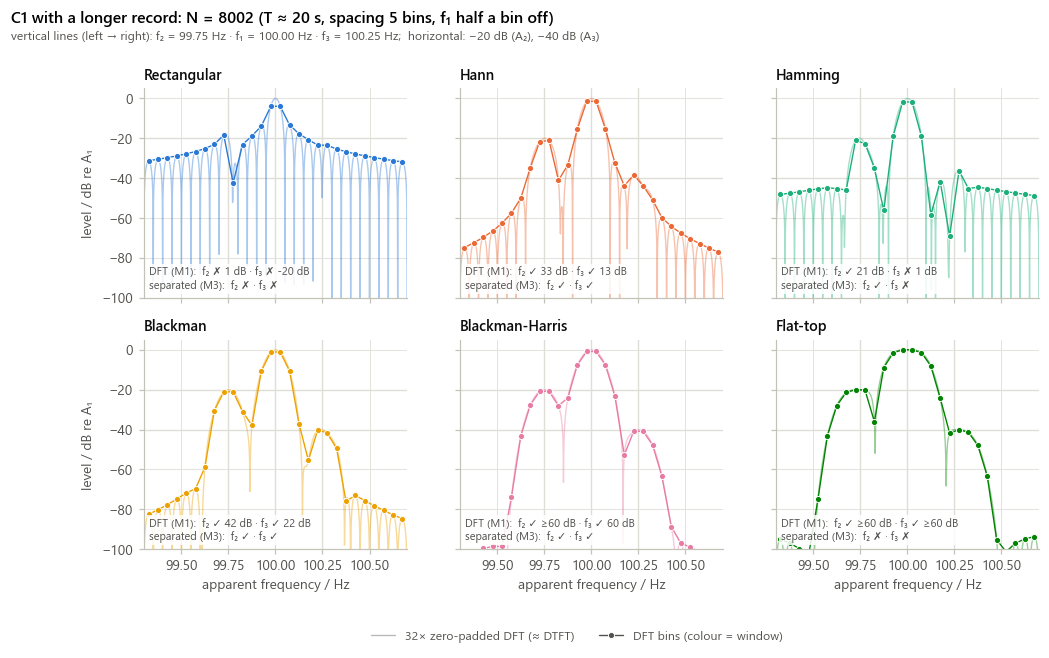

In [27]:
spectrum_panels(VARIANTS.loc[1], "C1 with a longer record: N = 8002 (T ≈ 20 s, spacing 5 bins, f₁ half a bin off)",
                "fig16_longer_record", N=8002, half_span=14, m3=True)

In [28]:
long = {}
vL = VARIANTS.loc[1]
AL, fL, cL = components(vL, N=8002)
faL = [alias(x, float(vL.fs))[0] for x in fL]
for name, wf in WINDOWS.items():
    w = wf(8002)
    long[name] = {"M1 f2 [dB]": m1_slr(cL, 1, w, faL[1], vL.fs), "M1 f3 [dB]": m1_slr(cL, 2, w, faL[2], vL.fs),
                  "M3 f2": m3_resolved(AL, fL, vL.fs, 8002, 1, w), "M3 f3": m3_resolved(AL, fL, vL.fs, 8002, 2, w)}
LONG = pd.DataFrame(long).T
display(LONG.apply(lambda col: col.map(lambda x: ("✓" if x else "✗") if isinstance(x, (bool, np.bool_))
                                        else ("≥60" if x >= SLR_CAP else f"{x:.1f}"))))

assert DMIN.loc[0].idxmin() == "Rectangular" and DMIN.loc[-40].idxmin() == "Blackman"
assert DMIN.loc[-60].idxmin() == "Blackman-Harris" and DMIN.loc[-20, "Hann"] == DMIN.loc[-20, "Hamming"] == DMIN.loc[-20].min()
assert LONG.loc[["Hann", "Blackman", "Blackman-Harris"], ["M3 f2", "M3 f3"]].all().all()
assert not LONG.loc[["Rectangular", "Flat-top"], ["M3 f2", "M3 f3"]].any().any()

,M1 f2 [dB],M1 f3 [dB],M3 f2,M3 f3
Rectangular,0.8,-19.6,✗,✗
Hann,32.6,12.5,✓,✓
Hamming,21.4,1.0,✓,✗
Blackman,42.3,22.2,✓,✓
Blackman-Harris,≥60,59.6,✓,✓
Flat-top,≥60,≥60,✗,✗


* **Equal amplitudes (0 dB):** the rectangular window separates two tones from 1.6 bins on, Hamming from 2.25,
  Hann from 2.5, Blackman from 2.9, Blackman–Harris from 3.25 and flat-top only from 5.25 bins — the ranking of
  the main-lobe widths.
* **−20 dB / −30 dB:** Hann and Hamming are best at −20 dB (2.75 bins), Hamming at −30 dB (2.75 bins; Hann 3.25);
  the rectangular window needs 8.6 / 28.6 bins because of its high sidelobes.
* **−40 dB / −50 dB:** Blackman is best (3.75 bins); Hamming's sidelobes (−43 dB, decaying slowly) are not low
  enough (9.6 / 32.6 bins) and the rectangular window never separates the tone.
* **≤ −60 dB:** Blackman–Harris is best (5 bins); flat-top works too (6.9 bins) but its main lobe is the widest.
* **For the task:** separating both weak tones (−20 and −40 dB at 0.25 Hz) needs T ≥ 15 s with Blackman — i.e.
  N ≥ 6000 at fₛ = 400 Hz, 7500 at 500 Hz, 9000 at 600 Hz, 12 000 at 800 Hz. Table 1 provides only T = 2.25–5 s.
  The longer record (T ≈ 20 s) confirms this: Hann, Blackman and Blackman–Harris separate both weak tones,
  Hamming only f₂, while the rectangular window shows neither and flat-top sees them in the DFT bins but cannot
  separate them (main lobes merge).

## 10. Interpretation

**Which window allows the best detection of weak tones located close to a strong tone?**
A low-sidelobe window, chosen according to how weak the tone is: Hann/Hamming down to about −30 dB, Blackman for
−40 … −50 dB, Blackman–Harris for −60 dB and below (Section 9). This only works if the tone lies outside the main lobe of
the strong one, i.e. the record must be long enough (here T ≥ 15 s). In the 15 short records of Table 1 no window
detects the weak tones on its own; what the DFT shows depends on coherent sampling: Hamming and Hann for T = 5 s
(both weak tones visible), the rectangular window for T = 4 s (perfect lines) and for T = 2.25–2.5 s (f₂ only).

**Which window provides the best separation of closely spaced frequencies?**
The rectangular window — it has the narrowest main lobe (half-width 1 bin, 6-dB bandwidth 1.21 bins) and
separates equal tones from 1.6 bins on; Hamming and Hann follow (2.25–2.5 bins), flat-top is the worst (5.25 bins).
Its advantage vanishes as soon as the amplitudes differ: for a −20 dB tone it needs 8.6 bins, for −40 dB it fails.

**How do the sidelobe level and the main-lobe width influence the observed spectra?**
The main-lobe width decides how close two tones may be before they merge into one lobe: a tone inside the main
lobe of another (0.56–1.25 bins in all variants, inside every window's lobe) can at most make the lobe asymmetric.
The sidelobe level and its decay set the floor under which weak tones farther away disappear: −13 dB with a
6 dB/octave decay (rectangular) hides a −40 dB tone at any spacing up to 40 bins, −58 dB (Blackman) or −92 dB
(Blackman–Harris) reveal it. Lower sidelobes always cost a wider main lobe and a lower coherent gain (corrected
here by 1/CG) — the classical trade-off. On a coherent tone a K-term window occupies exactly 2K − 1 DFT bins, which
is why Hann/Hamming (3 bins) leave the weak tones 1.25 bins away visible while Blackman (5) and wider windows cover
them.

**Why may the spectral representations of f₁, f₂ and f₃ differ despite their small frequency spacing?**
(1) **Bin alignment:** f₁ completes an integer number of periods in N samples in every variant and falls exactly on
a DFT bin (a single line with the rectangular window, Fig. 6 best case), whereas the 0.25 Hz offset puts f₂ and f₃
between bins (0.25–0.44 bin from the nearest bin) — they suffer scalloping loss and leak into all bins (worst-case type). Only for
T = 4 s (C4) are all three coherent. (2) **Aliasing:** all frequencies exceed fₛ/2, so the observed frequencies
are |f − m·fₛ|; mirrored aliases swap the positions of f₂ and f₃, and in variant 11 f₁ = fₛ/2 vanishes while f₂ and
f₃ fold onto the same frequency. (3) **Amplitude:** with −20 and −40 dB the weak tones sit at different heights of
the same leakage skirt, so one can be visible while the other is masked.

## 11. Conclusions

1. All 15 variants were computed. They form 7 configurations; the decisive parameter is the observation time
   T = N/fₛ, which sets the tone spacing to 0.5625–1.25 DFT bins. Every variant is aliased (f > fₛ/2), and variant 11
   is degenerate (f₁ = fₛ/2 is not sampled at all).
2. In these records the weak tones lie inside the main lobe of the strong tone for every window, so no window
   separates them intrinsically (M2, M3). The visible differences come from coherent sampling of f₁: the rectangular
   window is best for T = 4 s and T = 2.25–2.5 s, Hamming/Hann for T = 5 s, and Blackman, Blackman–Harris and
   flat-top never show a weak tone. These results are fragile: a 0.1-bin frequency error removes them.
3. In general, the choice depends on the amplitude ratio: rectangular for tones of similar amplitude, Hann/Hamming
   for −20 … −30 dB, Blackman for −40 … −50 dB and Blackman–Harris for −60 dB and below; flat-top is for amplitude
   measurement (0.01 dB scalloping loss), not for resolution.
4. To separate both weak tones of the task, the record must be about 3–7 times longer than in Table 1
   (T ≥ 15 s with Blackman); zero-padding only interpolates the spectrum and does not improve resolution.